# **PROJECT ΑΝΑΛΥΣΗΣ ΔΙΚΤΥΑΚΗΣ ΚΙΝΗΣΗΣ  - CIC-IDS-2017**
**Όνομα:** Μαρία <br>
**Επίθετο:** Δρούγκα <br>
**Έτος/Εξάμηνο:** 4/8 <br>
**Α.Μ:** 1100545 <br>


## **0. Setup Περιβάλλοντος**
Κάνω λήψη του dataset απο το Kaggle, καθώς και εγκατάσταση των απαραίτητων βιβλιοθηκών

In [2]:
from google.colab import files
uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [3]:
import os
os.makedirs('/root/.kaggle', exist_ok=True)
!cp kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json
!pip install -q kaggle

!kaggle datasets download -d chethuhn/network-intrusion-dataset -p /content/data

Dataset URL: https://www.kaggle.com/datasets/chethuhn/network-intrusion-dataset
License(s): CC0-1.0
100% 230M/230M [00:01<00:00, 150MB/s]



In [4]:
!unzip -q /content/data/network-intrusion-dataset.zip -d /content/data/CIC-IDS-2017
!ls -la /content/data/CIC-IDS-2017

total 863936
drwxr-xr-x 2 root root      4096 Sep 15 13:59 .
drwxr-xr-x 3 root root      4096 Sep 15 13:59 ..
-rw-r--r-- 1 root root  77123859 Aug 28  2023 Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
-rw-r--r-- 1 root root  76906168 Aug 28  2023 Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
-rw-r--r-- 1 root root  58316725 Aug 28  2023 Friday-WorkingHours-Morning.pcap_ISCX.csv
-rw-r--r-- 1 root root 176927918 Aug 28  2023 Monday-WorkingHours.pcap_ISCX.csv
-rw-r--r-- 1 root root  83102436 Aug 28  2023 Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
-rw-r--r-- 1 root root  52023263 Aug 28  2023 Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
-rw-r--r-- 1 root root 135078995 Aug 28  2023 Tuesday-WorkingHours.pcap_ISCX.csv
-rw-r--r-- 1 root root 225166395 Aug 28  2023 Wednesday-workingHours.pcap_ISCX.csv


## **Ερώτημα 1: EDA (Exploratory Data Analysis)**
### *1.1 Φόρτωση και Ένωση(merge) των csv αρχείων*
Το dataset μας, αποτελείται από 8 csv files, ένα ανά ημέρα/σενάριο επίθεσης. Εδώ τα φορτώνουμε και τα ενώνουμε σε ένα ενιαίο DataFrame, και παράλληλα καθορίζουμε τα ονόματα των στηλών (αφαίρεση κενών χαρακτήρων).

-> Επιβεβαίωση Αρχείων:

In [5]:
import pandas as pd
import numpy as np
import glob

csv_files = glob.glob('/content/data/CIC-IDS-2017/*.csv')
print(f"Βρέθηκαν {len(csv_files)} αρχεία:")
for f in csv_files:
    print(f)

Βρέθηκαν 8 αρχεία:
/content/data/CIC-IDS-2017/Tuesday-WorkingHours.pcap_ISCX.csv
/content/data/CIC-IDS-2017/Wednesday-workingHours.pcap_ISCX.csv
/content/data/CIC-IDS-2017/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
/content/data/CIC-IDS-2017/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
/content/data/CIC-IDS-2017/Monday-WorkingHours.pcap_ISCX.csv
/content/data/CIC-IDS-2017/Friday-WorkingHours-Morning.pcap_ISCX.csv
/content/data/CIC-IDS-2017/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
/content/data/CIC-IDS-2017/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv


-> Φόρτωση και Ένωση

In [6]:
dfs = []
for file in csv_files:
    df_temp = pd.read_csv(file, encoding='latin1', low_memory=False)
    dfs.append(df_temp)
    print(f"{file.split('/')[-1]}: {df_temp.shape}")

df = pd.concat(dfs, ignore_index=True)
print(f"\nΣυνολικό μέγεθος μετά το merge: {df.shape}")

Tuesday-WorkingHours.pcap_ISCX.csv: (445909, 79)
Wednesday-workingHours.pcap_ISCX.csv: (692703, 79)
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: (225745, 79)
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: (288602, 79)
Monday-WorkingHours.pcap_ISCX.csv: (529918, 79)
Friday-WorkingHours-Morning.pcap_ISCX.csv: (191033, 79)
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: (286467, 79)
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: (170366, 79)

Συνολικό μέγεθος μετά το merge: (2830743, 79)


In [7]:
df.columns = df.columns.str.strip()
print(df.columns.tolist())

['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count

### *1.2 Δομή του dataset και έλεγχος για Missing Values, Infinite Values καθώς και Duplicates*
Εξετάζουμε τη δομή του dataset (πλήθος γραμμών/στηλών, τύποι δεδομένων), <br> εντοπίζουμε
προβληματικές τιμές (Inf (στη στήλη Flow Bytes/s λόγω διαίρεσης με το μηδέν σε flows
με Flow Duration = 0)),<br> ελλιπείς τιμές (NaN),<br> και διπλότυπες εγγραφές.

-> Η βασική δομή του dataset:

In [8]:
print("Shape:", df.shape)
print("\nΤύποι δεδομένων:")
print(df.dtypes.value_counts())

print("\nΧρήση μνήμης:")
print(f"{df.memory_usage(deep=True).sum() / 1024**3:.2f} GB")

df.info(memory_usage='deep')

Shape: (2830743, 79)

Τύποι δεδομένων:
int64      54
float64    24
object      1
Name: count, dtype: int64

Χρήση μνήμης:
1.79 GB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2830743 entries, 0 to 2830742
Data columns (total 79 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   Destination Port             int64  
 1   Flow Duration                int64  
 2   Total Fwd Packets            int64  
 3   Total Backward Packets       int64  
 4   Total Length of Fwd Packets  int64  
 5   Total Length of Bwd Packets  int64  
 6   Fwd Packet Length Max        int64  
 7   Fwd Packet Length Min        int64  
 8   Fwd Packet Length Mean       float64
 9   Fwd Packet Length Std        float64
 10  Bwd Packet Length Max        int64  
 11  Bwd Packet Length Min        int64  
 12  Bwd Packet Length Mean       float64
 13  Bwd Packet Length Std        float64
 14  Flow Bytes/s                 float64
 15  Flow Packets/s               float64
 

-> Έλεγχος για Inf values
(Οι τιμές Inf εμφανίζονται συνήθως όταν το Flow Duration είναι 0 (διαίρεση με το μηδέν)):

In [9]:
# Οι τιμές Inf εμφανίζονται συνήθως όταν το Flow Duration είναι 0 (διαίρεση με το μηδέν)
inf_counts = np.isinf(df.select_dtypes(include=[np.number])).sum()
inf_counts = inf_counts[inf_counts > 0]
print("Στήλες με Inf τιμές:")
print(inf_counts)

Στήλες με Inf τιμές:
Flow Bytes/s      1509
Flow Packets/s    2867
dtype: int64


-> Έλεγχος για Missing values (NaN):


In [10]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing Count', ascending=False)
print(missing_df)

              Missing Count  Missing %
Flow Bytes/s           1358   0.047973


-> Έλεγχος για Duplicates:


In [11]:
dup_count = df.duplicated().sum()
print(f"Αριθμός διπλότυπων γραμμών: {dup_count} ({dup_count/len(df)*100:.2f}%)")

Αριθμός διπλότυπων γραμμών: 308381 (10.89%)


-> Αντικατάσταση Inf με NaN ώστε να τα διαχειριστώ ενιαία, και μετά αφαίρεση των γραμμών NaN (αμελητέο ποσοστό, δεν χρειάζεται imputation):

In [12]:
df.replace([np.inf, -np.inf], np.nan, inplace=True)

print("NaN πριν την αφαίρεση:", df.isnull().sum().sum())

rows_before = len(df)
df.dropna(inplace=True)
rows_after = len(df)

print(f"Γραμμές πριν: {rows_before}")
print(f"Γραμμές μετά: {rows_after}")
print(f"Αφαιρέθηκαν: {rows_before - rows_after} γραμμές ({(rows_before-rows_after)/rows_before*100:.3f}%)")

NaN πριν την αφαίρεση: 5734
Γραμμές πριν: 2830743
Γραμμές μετά: 2827876
Αφαιρέθηκαν: 2867 γραμμές (0.101%)


-> Αφαίρεση των Duplicates:

In [13]:
rows_before = len(df)
df.drop_duplicates(inplace=True)
rows_after = len(df)

print(f"Γραμμές πριν: {rows_before}")
print(f"Γραμμές μετά: {rows_after}")
print(f"Αφαιρέθηκαν {rows_before - rows_after} διπλότυπα ({(rows_before-rows_after)/rows_before*100:.2f}%)")
print(f"\nΤελικό shape: {df.shape}")

Γραμμές πριν: 2827876
Γραμμές μετά: 2520798
Αφαιρέθηκαν 307078 διπλότυπα (10.86%)

Τελικό shape: (2520798, 79)


-> Επιβεβαίωση του clean dataset:

In [14]:
print("Τελικός έλεγχος:")
print(f"Inf values: {np.isinf(df.select_dtypes(include=[np.number])).sum().sum()}")
print(f"NaN values: {df.isnull().sum().sum()}")
print(f"Duplicates: {df.duplicated().sum()}")
print(f"Shape: {df.shape}")

Τελικός έλεγχος:
Inf values: 0
NaN values: 0
Duplicates: 0
Shape: (2520798, 79)


### *1.3 Ανάλυση Μεταβλητής Στόχου (LABEL)*
Εξετάζουμε την κατανομή των κλάσεων της μεταβλητής Label, προκειμένου να εντοπίσουμε
το επίπεδο ανισορροπίας (class imbalance) που θα πρέπει να ληφθεί υπόψη στο στάδιο
της ταξινόμησης. <br>
-> Κατανομή Κλάσεων:

In [15]:
label_counts = df['Label'].value_counts()
label_pct = df['Label'].value_counts(normalize=True) * 100

label_summary = pd.DataFrame({'Count': label_counts, 'Percentage': label_pct.round(3)})
print(label_summary)
print(f"\nΣυνολικός αριθμός μοναδικών κλάσεων: {df['Label'].nunique()}")

                                Count  Percentage
Label                                            
BENIGN                        2095057      83.111
DoS Hulk                       172846       6.857
DDoS                           128014       5.078
PortScan                        90694       3.598
DoS GoldenEye                   10286       0.408
FTP-Patator                      5931       0.235
DoS slowloris                    5385       0.214
DoS Slowhttptest                 5228       0.207
SSH-Patator                      3219       0.128
Bot                              1948       0.077
Web Attack ï¿½ Brute Force       1470       0.058
Web Attack ï¿½ XSS                652       0.026
Infiltration                       36       0.001
Web Attack ï¿½ Sql Injection       21       0.001
Heartbleed                         11       0.000

Συνολικός αριθμός μοναδικών κλάσεων: 15


-> Οπτικοποίηση (bar chart, log scale):

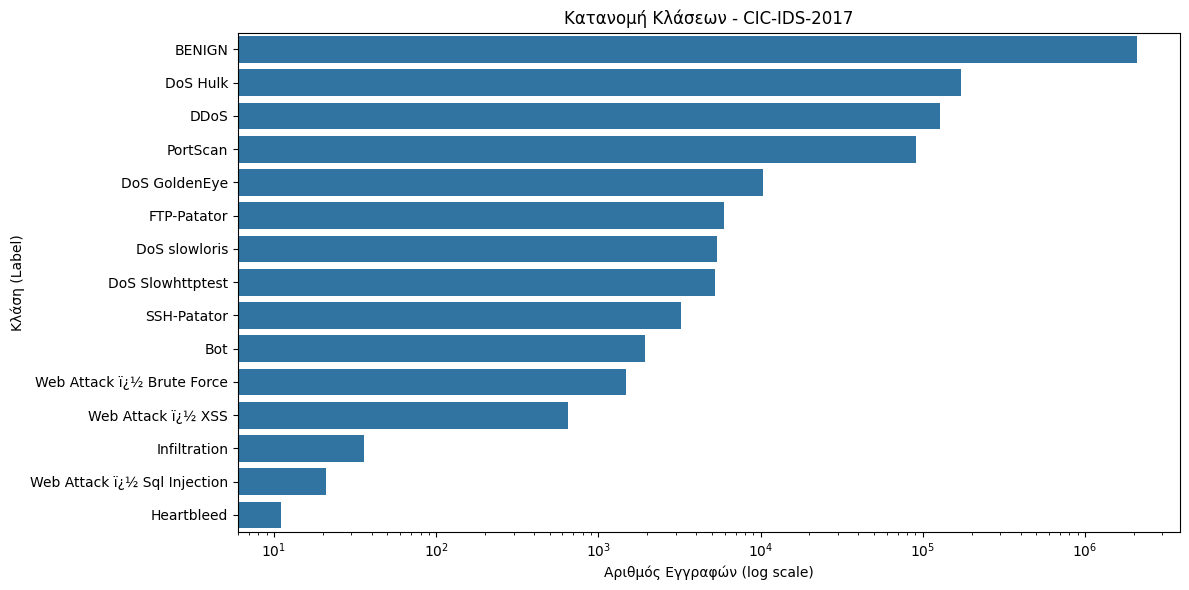

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.barplot(x=label_counts.values, y=label_counts.index)

plt.xlabel('Αριθμός Εγγραφών (log scale)')
plt.ylabel('Κλάση (Label)')
plt.title('Κατανομή Κλάσεων - CIC-IDS-2017')
plt.xscale('log')  # log scale γιατί η BENIGN κυριαρχεί δραματικά
plt.tight_layout()

plt.savefig('label_distribution.png', dpi=150)
plt.show()

-> Ποσοτικοποίηση της ανισορροπίας:

In [17]:
majority_class = label_counts.idxmax()
majority_pct = label_pct.max()
minority_class = label_counts.idxmin()
minority_pct = label_pct.min()

print(f"Πλειοψηφική κλάση: {majority_class} ({majority_pct:.2f}%)")
print(f"Μειοψηφική κλάση: {minority_class} ({minority_pct:.4f}%)")
print(f"Λόγος ανισορροπίας (imbalance ratio): {label_counts.max() / label_counts.min():.0f}:1")

Πλειοψηφική κλάση: BENIGN (83.11%)
Μειοψηφική κλάση: Heartbleed (0.0004%)
Λόγος ανισορροπίας (imbalance ratio): 190460:1


In [18]:
# Έλεγχος μοναδικών τιμών με το πρόβλημα
df['Label'] = df['Label'].str.replace('ï¿½', '-', regex=False)

print(df['Label'].unique())

['BENIGN' 'FTP-Patator' 'SSH-Patator' 'DoS slowloris' 'DoS Slowhttptest'
 'DoS Hulk' 'DoS GoldenEye' 'Heartbleed' 'DDoS' 'Infiltration' 'Bot'
 'PortScan' 'Web Attack - Brute Force' 'Web Attack - XSS'
 'Web Attack - Sql Injection']


### *1.4 Στατιστικη Περιγραφή Μεταβλητών*
Υπολογίζω τα βασικά περιγραφικά στατιστικά <br>
(μέσος όρος,<br> τυπική απόκλιση,<br> ελάχιστο,<br>
μέγιστο,<br> τεταρτημόρια)<br> για όλες τις αριθμητικές μεταβλητές του dataset.

In [19]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

desc_stats = df.describe().T  # .T = transpose, ώστε κάθε γραμμή να είναι μια στήλη
desc_stats

# Αποθήκευση σε αρχείο
desc_stats.to_csv('descriptive_statistics.csv')
print("Αποθηκεύτηκε. Πρώτες 10 στήλες:")
desc_stats.head(10)

# Εντοπισμός στηλών με χαμηλή ή και μηδενική variance(διακύμανση)
# (σημαντικό για την μετέπειτα επιλογή χαρακτηριστικών - feature extraction)
zero_variance = desc_stats[desc_stats['std'] == 0]
print("Στήλες με μηδενική διακύμανση (σταθερή τιμή σε όλες τις γραμμές):")
print(zero_variance.index.tolist())

low_variance = desc_stats[(desc_stats['std'] > 0) & (desc_stats['std'] < 0.01)]
print("\nΣτήλες με πολύ χαμηλή διακύμανση (<0.01):")
print(low_variance.index.tolist())


Αποθηκεύτηκε. Πρώτες 10 στήλες:
Στήλες με μηδενική διακύμανση (σταθερή τιμή σε όλες τις γραμμές):
['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

Στήλες με πολύ χαμηλή διακύμανση (<0.01):
['Fwd URG Flags', 'CWE Flag Count']


In [20]:
zero_var_cols = ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk',
                  'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk',
                  'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

for col in zero_var_cols:
    print(f"{col}: μοναδικές τιμές = {df[col].unique()}")

Bwd PSH Flags: μοναδικές τιμές = [0]
Bwd URG Flags: μοναδικές τιμές = [0]
Fwd Avg Bytes/Bulk: μοναδικές τιμές = [0]
Fwd Avg Packets/Bulk: μοναδικές τιμές = [0]
Fwd Avg Bulk Rate: μοναδικές τιμές = [0]
Bwd Avg Bytes/Bulk: μοναδικές τιμές = [0]
Bwd Avg Packets/Bulk: μοναδικές τιμές = [0]
Bwd Avg Bulk Rate: μοναδικές τιμές = [0]


### *1.5 Οπτικοποίηση Κατανομών και Εντοπισμός Ακραίων Τιμών*
Εδώ, εξετάζω την μορφή των κατανομών των features και εντοπίζω ακραίες τιμές (outliers) μέσω boxplots. <br>
-> Histograms για τα βασικά features:

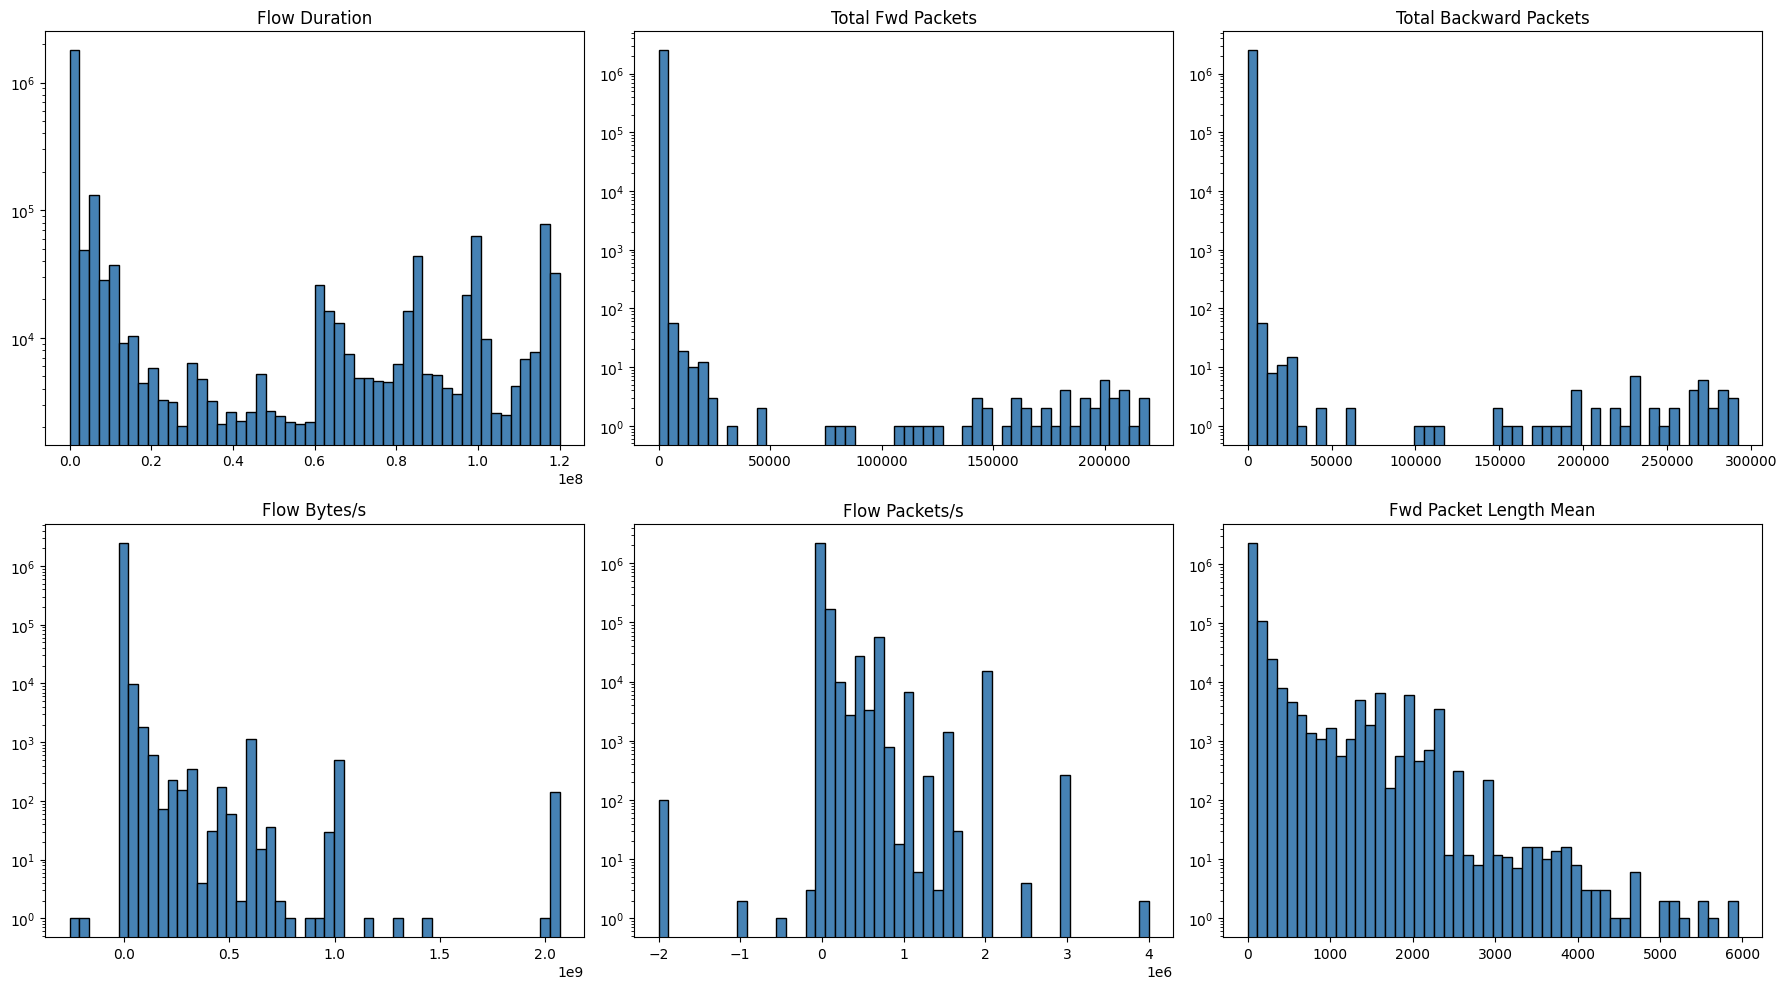

In [21]:
key_features = ['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets',
                 'Flow Bytes/s', 'Flow Packets/s', 'Fwd Packet Length Mean']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(key_features):
    axes[i].hist(df[col], bins=50, color='steelblue', edgecolor='black')
    axes[i].set_title(col)
    axes[i].set_yscale('log')  # log scale γιατί οι κατανομές είναι πολύ δεξιόστροφες (right-skewed)

plt.tight_layout()
plt.savefig('feature_distributions.png', dpi=150)
plt.show()

-> Boxplots για εντοπισμό των outliers:

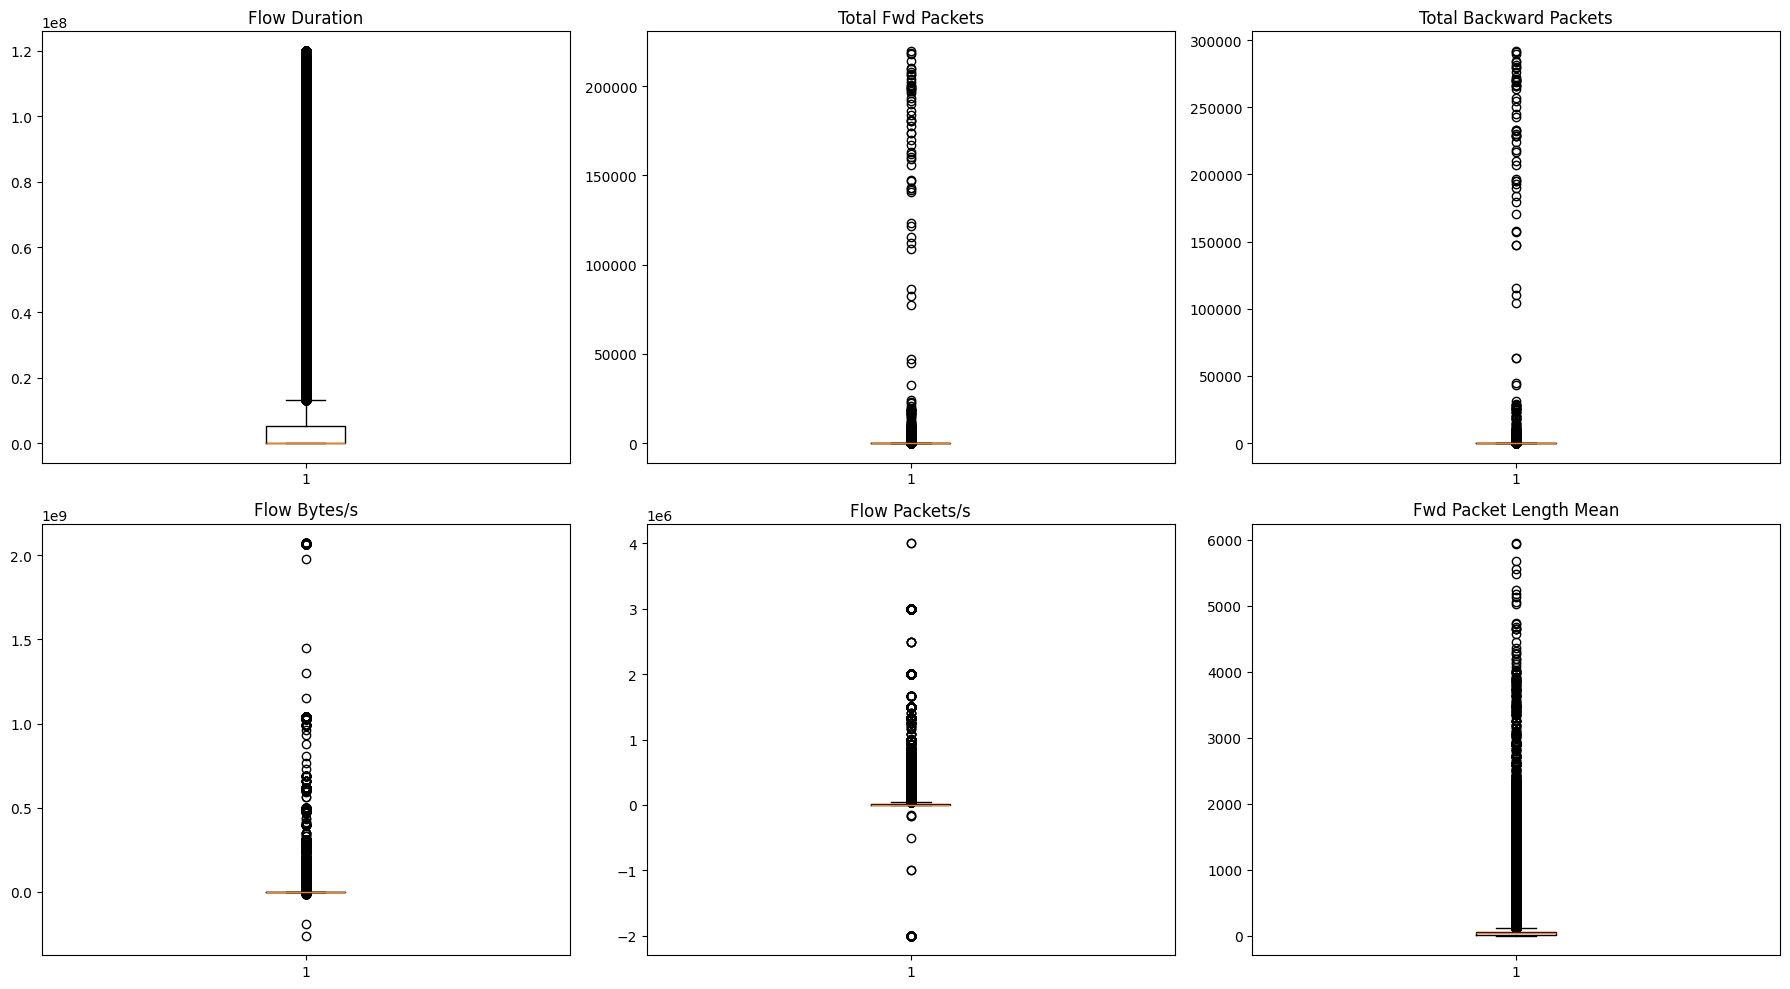

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(key_features):
    axes[i].boxplot(df[col], vert=True)
    axes[i].set_title(col)

plt.tight_layout()
plt.savefig('feature_boxplots.png', dpi=150)
plt.show()

In [23]:
neg_bytes = (df['Flow Bytes/s'] < 0).sum()
neg_packets = (df['Flow Packets/s'] < 0).sum()

print(f"Αρνητικές τιμές σε Flow Bytes/s: {neg_bytes}")
print(f"Αρνητικές τιμές σε Flow Packets/s: {neg_packets}")

print("\nΔείγμα γραμμών με αρνητικές τιμές:")
df[(df['Flow Bytes/s'] < 0) | (df['Flow Packets/s'] < 0)][
    ['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets',
     'Flow Bytes/s', 'Flow Packets/s', 'Label']
].head(10)

Αρνητικές τιμές σε Flow Bytes/s: 78
Αρνητικές τιμές σε Flow Packets/s: 107

Δείγμα γραμμών με αρνητικές τιμές:


,Flow Duration,Total Fwd Packets,Total Backward Packets,Flow Bytes/s,Flow Packets/s,Label
24737,-1,1,1,0.0,-2000000.0,BENIGN
27021,-1,1,1,0.0,-2000000.0,BENIGN
74737,-1,1,1,0.0,-2000000.0,BENIGN
90837,-1,1,1,0.0,-2000000.0,BENIGN
103704,-1,1,1,0.0,-2000000.0,BENIGN
112258,-1,1,1,0.0,-2000000.0,BENIGN
119674,-1,1,1,0.0,-2000000.0,BENIGN
124890,-1,1,1,0.0,-2000000.0,BENIGN
142333,-1,1,1,0.0,-2000000.0,BENIGN
203778,-1,1,1,0.0,-2000000.0,BENIGN


In [24]:
# Ελέγχουμε αν τα ακραία Total Fwd Packets συνδέονται με επιθέσεις
extreme_packets = df[df['Total Fwd Packets'] > 50000]
print("Κατανομή Label στα flows με >50000 Fwd Packets:")
print(extreme_packets['Label'].value_counts())

Κατανομή Label στα flows με >50000 Fwd Packets:
Label
BENIGN    51
Name: count, dtype: int64


-> Αφαιρώ τις μη έγκυρες αρνητικές τιμές.<br>
Οι μεταβλητές Flow Duration, Flow Bytes/s και Flow Packets/s δεν αναμένεται να λαμβάνουν αρνητικές τιμές. Εντοπίστηκαν λίγες εγγραφές με τέτοιες τιμές, οι οποίες αφαιρούνται καθώς θεωρούνται μη έγκυρες. Η αφαίρεση αφορά πολύ μικρό ποσοστό του dataset.

In [25]:
rows_before = len(df)

df = df[df['Flow Duration'] >= 0]
df = df[df['Flow Bytes/s'] >= 0]
df = df[df['Flow Packets/s'] >= 0]

rows_after = len(df)
print(f"Γραμμές πριν: {rows_before}")
print(f"Γραμμές μετά: {rows_after}")
print(f"Αφαιρέθηκαν {rows_before - rows_after} γραμμές με φυσικά αδύνατες (αρνητικές) τιμές")

Γραμμές πριν: 2520798
Γραμμές μετά: 2520691
Αφαιρέθηκαν 107 γραμμές με φυσικά αδύνατες (αρνητικές) τιμές


### *1.6 Correlation Analysis*
Διερευνούμε τις συσχετίσεις μεταξύ των αριθμητικών χαρακτηριστικών με στόχο τον
εντοπισμό πλεονασματικών (redundant) μεταβλητών, οι οποίες θα αφαιρεθούν στο στάδιο
του feature selection. <br>
-> Yπολογισμός Correlation Matrix:

In [26]:
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()
print(f"Διαστάσεις correlation matrix: {corr_matrix.shape}")

Διαστάσεις correlation matrix: (78, 78)


-> Heatmap:

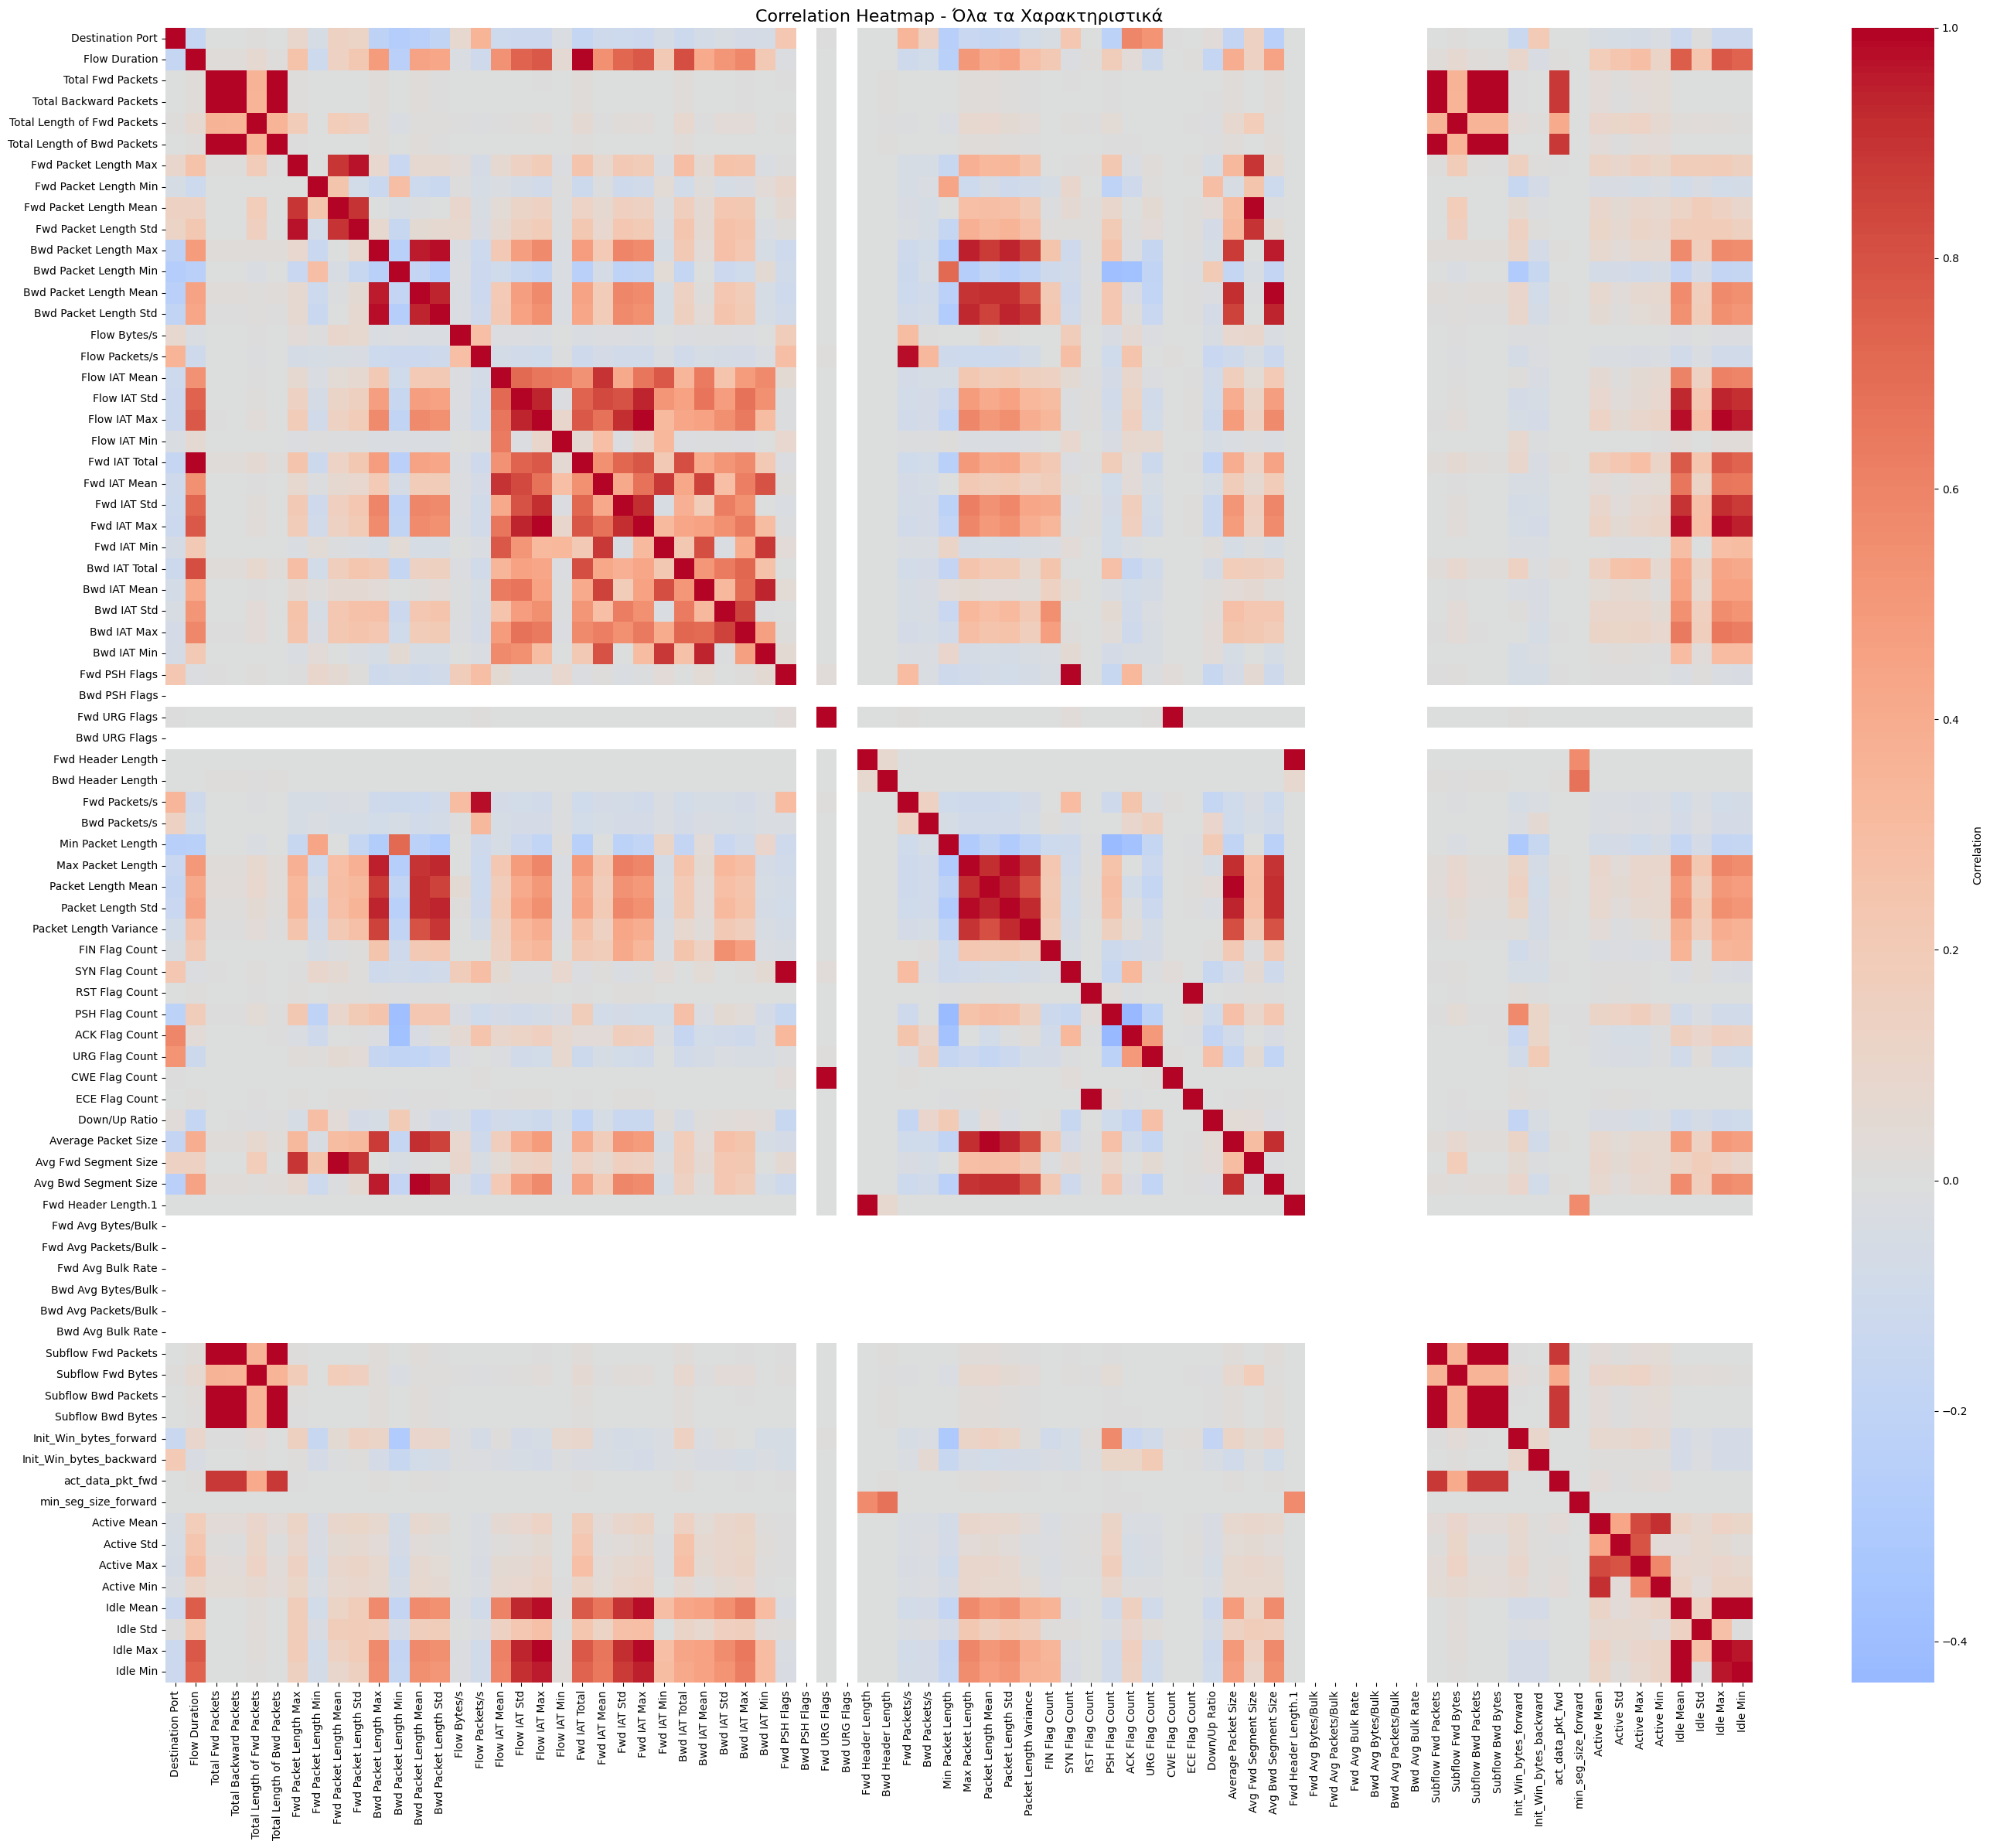

In [27]:
plt.figure(figsize=(28, 24))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0,
            xticklabels=True, yticklabels=True,
            cbar_kws={'label': 'Correlation'})
plt.title('Correlation Heatmap - Όλα τα Χαρακτηριστικά', fontsize=16)
plt.tight_layout()
plt.savefig('correlation_heatmap_full.png', dpi=150)
plt.show()

-> ζεύγη με υψηλή συσχέτιση (corr>0.95):

In [28]:
# Παίρνουμε μόνο το πάνω τριγωνικό μέρος (αποφεύγουμε διπλότυπα ζεύγη)
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

high_corr_pairs = []
for col in upper_triangle.columns:
    for idx in upper_triangle.index:
        val = upper_triangle.loc[idx, col]
        if pd.notnull(val) and abs(val) > 0.95:
            high_corr_pairs.append((idx, col, val))

high_corr_df = pd.DataFrame(high_corr_pairs, columns=['Feature 1', 'Feature 2', 'Correlation'])
high_corr_df = high_corr_df.sort_values('Correlation', key=abs, ascending=False)
print(f"Βρέθηκαν {len(high_corr_df)} ζεύγη με |correlation| > 0.95:")
high_corr_df

Βρέθηκαν 39 ζεύγη με |correlation| > 0.95:


,Feature 1,Feature 2,Correlation
23,Total Backward Packets,Subflow Bwd Packets,1.000000
18,Total Fwd Packets,Subflow Fwd Packets,1.000000
17,Fwd Header Length,Fwd Header Length.1,1.000000
16,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000
14,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000
11,Fwd URG Flags,CWE Flag Count,1.000000
10,Fwd PSH Flags,SYN Flag Count,1.000000
28,Total Length of Bwd Packets,Subflow Bwd Bytes,1.000000
21,Total Length of Fwd Packets,Subflow Fwd Bytes,0.999999
19,Total Backward Packets,Subflow Fwd Packets,0.999070


-> Εντοπισμός "οικογενειών" υψηλά συσχετισμένων χαρακτηριστικών, μέσω graph connected component. <br>
Τα χαρακτηριστικά με απόλυτη συσχέτιση μεγαλύτερη από 0.95 τα ομαδοποιπώ σε connected components. Από κάθε ομάδα διατηρείται ένα αντιπροσωπευτικό χαρακτηριστικό, ώστε να μειωθεί η πλεονάζουσα πληροφορία και η διάσταση του dataset.

In [29]:
import networkx as nx

G = nx.Graph()
G.add_nodes_from(corr_matrix.columns)
for _, row in high_corr_df.iterrows():
    G.add_edge(row['Feature 1'], row['Feature 2'])

groups = [g for g in nx.connected_components(G) if len(g) > 1]

print(f"Βρέθηκαν {len(groups)} ομάδες αλληλοσυσχετιζόμενων χαρακτηριστικών:\n")

to_drop_correlation = set()
for i, group in enumerate(sorted(groups, key=len, reverse=True)):
    group = sorted(group)
    keep = group[0]
    drop = group[1:]
    to_drop_correlation.update(drop)
    print(f"Ομάδα {i+1} ({len(group)} χαρακτηριστικά): {group}")
    print(f"   → Κρατάμε: '{keep}'  |  Αφαιρούμε: {drop}\n")

print(f"ΣΥΝΟΛΟ στηλών προς αφαίρεση λόγω υψηλής συσχέτισης: {len(to_drop_correlation)}")

Βρέθηκαν 14 ομάδες αλληλοσυσχετιζόμενων χαρακτηριστικών:

Ομάδα 1 (6 χαρακτηριστικά): ['Subflow Bwd Bytes', 'Subflow Bwd Packets', 'Subflow Fwd Packets', 'Total Backward Packets', 'Total Fwd Packets', 'Total Length of Bwd Packets']
   → Κρατάμε: 'Subflow Bwd Bytes'  |  Αφαιρούμε: ['Subflow Bwd Packets', 'Subflow Fwd Packets', 'Total Backward Packets', 'Total Fwd Packets', 'Total Length of Bwd Packets']

Ομάδα 2 (5 χαρακτηριστικά): ['Flow IAT Max', 'Fwd IAT Max', 'Idle Max', 'Idle Mean', 'Idle Min']
   → Κρατάμε: 'Flow IAT Max'  |  Αφαιρούμε: ['Fwd IAT Max', 'Idle Max', 'Idle Mean', 'Idle Min']

Ομάδα 3 (4 χαρακτηριστικά): ['Avg Bwd Segment Size', 'Bwd Packet Length Max', 'Bwd Packet Length Mean', 'Bwd Packet Length Std']
   → Κρατάμε: 'Avg Bwd Segment Size'  |  Αφαιρούμε: ['Bwd Packet Length Max', 'Bwd Packet Length Mean', 'Bwd Packet Length Std']

Ομάδα 4 (2 χαρακτηριστικά): ['Flow Duration', 'Fwd IAT Total']
   → Κρατάμε: 'Flow Duration'  |  Αφαιρούμε: ['Fwd IAT Total']

Ομάδα 5 (2 χ

### *1.7 Τελική Λίστα Feature Selection*
Με βάση τα χαρακτηριστικά μηδενικής διακύμανσης και τα πλεονάζοντα χαρακτηριστικά που προέκυψαν από την ανάλυση υψηλής συσχέτισης, καταλήγουμε στην τελική λίστα
χαρακτηριστικών προς αφαίρεση. Τα χαρακτηριστικά αυτά αφαιρούνται πριν από την εκπαίδευση των μοντέλων.

In [30]:
# Κριτήριο 1: Μηδενική διακύμανση
zero_var_cols = ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk',
                  'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk',
                  'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

# Κριτήριο 2: Υψηλή συσχέτιση (>0.95) - από το Cell 31
# to_drop_correlation υπάρχει ήδη ως μεταβλητή

all_cols_to_drop = set(zero_var_cols) | to_drop_correlation
print(f"Στήλες από μηδενική διακύμανση: {len(zero_var_cols)}")
print(f"Στήλες από υψηλή συσχέτιση: {len(to_drop_correlation)}")
print(f"Επικάλυψη μεταξύ των δύο κριτηρίων: {len(set(zero_var_cols) & to_drop_correlation)}")
print(f"ΣΥΝΟΛΟ μοναδικών στηλών προς αφαίρεση: {len(all_cols_to_drop)}")
print(f"\nΤελικός αριθμός χαρακτηριστικών που θα διατηρηθούν: {df.shape[1] - len(all_cols_to_drop)} (από {df.shape[1]}, εκ των οποίων 1 είναι το Label)")

print("\nΠλήρης λίστα προς αφαίρεση:")
for col in sorted(all_cols_to_drop):
    print(f"  - {col}")

Στήλες από μηδενική διακύμανση: 8
Στήλες από υψηλή συσχέτιση: 23
Επικάλυψη μεταξύ των δύο κριτηρίων: 0
ΣΥΝΟΛΟ μοναδικών στηλών προς αφαίρεση: 31

Τελικός αριθμός χαρακτηριστικών που θα διατηρηθούν: 48 (από 79, εκ των οποίων 1 είναι το Label)

Πλήρης λίστα προς αφαίρεση:
  - Bwd Avg Bulk Rate
  - Bwd Avg Bytes/Bulk
  - Bwd Avg Packets/Bulk
  - Bwd PSH Flags
  - Bwd Packet Length Max
  - Bwd Packet Length Mean
  - Bwd Packet Length Std
  - Bwd URG Flags
  - Fwd Avg Bulk Rate
  - Fwd Avg Bytes/Bulk
  - Fwd Avg Packets/Bulk
  - Fwd Header Length.1
  - Fwd IAT Max
  - Fwd IAT Total
  - Fwd Packet Length Mean
  - Fwd Packet Length Std
  - Fwd Packets/s
  - Fwd URG Flags
  - Idle Max
  - Idle Mean
  - Idle Min
  - Packet Length Mean
  - Packet Length Std
  - RST Flag Count
  - SYN Flag Count
  - Subflow Bwd Packets
  - Subflow Fwd Packets
  - Total Backward Packets
  - Total Fwd Packets
  - Total Length of Bwd Packets
  - Total Length of Fwd Packets


-> Feature Selection:

In [31]:
df_selected = df.drop(columns=list(all_cols_to_drop))
print(f"Shape πριν: {df.shape}")
print(f"Shape μετά: {df_selected.shape}")
print(f"\nΤελικές στήλες που διατηρήθηκαν ({df_selected.shape[1]}):")
print(df_selected.columns.tolist())

#save dataset
df_selected.to_csv('/content/data/cleaned_selected_dataset.csv', index=False)
print("Αποθηκεύτηκε επιτυχώς.")
print(f"Μέγεθος αρχείου: shape = {df_selected.shape}")

Shape πριν: (2520691, 79)
Shape μετά: (2520691, 48)

Τελικές στήλες που διατηρήθηκαν (48):
['Destination Port', 'Flow Duration', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Bwd Packet Length Min', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Variance', 'FIN Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count', 'Down/Up Ratio', 'Average Packet Size', 'Avg Fwd Segment Size', 'Avg Bwd Segment Size', 'Subflow Fwd Bytes', 'Subflow Bwd Bytes', 'Init_Win_bytes_forward', 'Init_Win_bytes_backward', 'act_data_pkt_fwd', 'min_seg_size_forward', 'Active Mean', 'Active Std', 'Active Max', 'Active Min', 'Idle Std', 'Label']
Αποθηκεύτηκε επι

## **Ερώτημα 2 Κατηγοριοποίηση**
### *2.1 Προετοιμασία Δεδομένων*

Προετοιμάζουμε τα δεδομένα για εκπαίδευση: κωδικοποίηση της μεταβλητής στόχου,
διαχωρισμός σε train/validation/test, και κλιμάκωση χαρακτηριστικών.

In [32]:
# Αν συνεχίζετε στο ίδιο session, το df_selected υπάρχει ήδη - παραλείψτε αυτό το cell
# Αλλιώς: df_selected = pd.read_csv('/content/data/cleaned_selected_dataset.csv')

print(df_selected.shape)
print(df_selected['Label'].value_counts())

(2520691, 48)
Label
BENIGN                        2094950
DoS Hulk                       172846
DDoS                           128014
PortScan                        90694
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1948
Web Attack - Brute Force         1470
Web Attack - XSS                  652
Infiltration                       36
Web Attack - Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [1]:
import gc
import pandas as pd
import numpy as np

df_selected = pd.read_csv('/content/data/cleaned_selected_dataset.csv')

float_cols = df_selected.select_dtypes(include=['float64']).columns
df_selected[float_cols] = df_selected[float_cols].astype('float32')

int_cols = df_selected.select_dtypes(include=['int64']).columns
for col in int_cols:
    df_selected[col] = pd.to_numeric(df_selected[col], downcast='integer')

print(f"Μνήμη dataset: {df_selected.memory_usage(deep=True).sum() / 1024**3:.2f} GB")
print(df_selected.shape)

Μνήμη dataset: 0.50 GB
(2520691, 48)


In [2]:
from sklearn.preprocessing import LabelEncoder

X = df_selected.drop(columns=['Label'])
y_raw = df_selected['Label']

le = LabelEncoder()
y = le.fit_transform(y_raw)

print("Κλάσεις και αντίστοιχοι κωδικοί:")
for i, cls in enumerate(le.classes_):
    print(f"  {i}: {cls}")

Κλάσεις και αντίστοιχοι κωδικοί:
  0: BENIGN
  1: Bot
  2: DDoS
  3: DoS GoldenEye
  4: DoS Hulk
  5: DoS Slowhttptest
  6: DoS slowloris
  7: FTP-Patator
  8: Heartbleed
  9: Infiltration
  10: PortScan
  11: SSH-Patator
  12: Web Attack - Brute Force
  13: Web Attack - Sql Injection
  14: Web Attack - XSS


-> Train/Val/Test split:

In [3]:
from sklearn.model_selection import train_test_split

# Πρώτα: 80% train+val, 20% test (held-out)
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Μετά: 80% train, 20% val (από το trainval) -> 64%/16%/20% συνολικά
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.20, stratify=y_trainval, random_state=42
)

print(f"Train: {X_train.shape}")
print(f"Validation: {X_val.shape}")
print(f"Test: {X_test.shape}")

Train: (1613241, 47)
Validation: (403311, 47)
Test: (504139, 47)


-> Κλιμάκωση χαρακτηριστικών (fit ΜΟΝΟ στο train, apply σε όλα):

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Κλιμάκωση ολοκληρώθηκε.")
print(f"Mean (πρέπει να είναι ~0): {X_train_scaled.mean():.4f}")
print(f"Std (πρέπει να είναι ~1): {X_train_scaled.std():.4f}")

Κλιμάκωση ολοκληρώθηκε.
Mean (πρέπει να είναι ~0): -0.0000
Std (πρέπει να είναι ~1): 1.0000


### *2.2 Διαχείριση Class Imbalance*
Λόγω του μεγέθους του dataset (>2.5 εκατομμύρια εγγραφές), η χρήση τεχνικών
oversampling όπως το SMOTE κρίθηκε υπολογιστικά μη πρακτική. Αντ' αυτού,
χρησιμοποιήθηκε η παράμετρος class_weight='balanced', η οποία σταθμίζει αντιστρόφως
ανάλογα με τη συχνότητα κάθε κλάσης κατά την εκπαίδευση, χωρίς επιπλέον υπολογιστικό
κόστος ή αλλοίωση του πραγματικού μεγέθους δείγματος.

### *2.3 Δημιουργία δείγματος για GridSearch tuning*

In [5]:
from sklearn.model_selection import train_test_split
import gc

TUNING_SAMPLE_SIZE = 150000

X_train_tune, _, y_train_tune, _ = train_test_split(
    X_train_scaled, y_train,
    train_size=TUNING_SAMPLE_SIZE,
    stratify=y_train,
    random_state=42
)

print(f"Δείγμα tuning: {X_train_tune.shape}")

import pandas as pd
print(pd.Series(y_train_tune).value_counts().sort_index())

Δείγμα tuning: (150000, 47)
0     124665
1        116
2       7618
3        612
4      10286
5        311
6        320
7        353
8          1
9          2
10      5397
11       192
12        87
13         1
14        39
Name: count, dtype: int64


## *2.4 Logistic Regression*

Εφαρμόζουμε GridSearch βελτιστοποίησης υπερπαραμέτρων σε δύο σενάρια: <br> (α) Χωρίς Cross-Validation: Αξιολόγηση μέσω απλού train/validation split. Κάθε συνδυασμός υπερπαραμέτρων εκπαιδεύεται στο tuning training sample και αξιολογείται στο validation set.  <br> (β) Με Cross-Validation: Χρησιμοποιείται 3-fold K-Fold Cross-Validation. <br> Σημειώνεται ότι λόγω της παρουσίας κλάσεων με ελάχιστα δείγματα (μικρών κλάσεων του dataset μας),
(π.χ. Heartbleed, Web Attack - Sql Injection), στο δείγμα εκπαίδευσης που
χρησιμοποιείται για το tuning, χρησιμοποιήθηκε τυπικό KFold αντί για StratifiedKFold,
καθώς η στρωματοποίηση θα απαιτούσε τουλάχιστον k δείγματα ανά κλάση (ορισμένες κλάσεις διαθέτουν λιγότερα από 3 δείγματα στο tuning sample).

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import classification_report, f1_score
import time

param_grid_lr = {
    'C': [0.01, 0.1, 1, 10],
    'penalty': ['l2'],
    'solver': ['lbfgs']
}

In [7]:
# Χειροκίνητο GridSearch χωρίς CV: εκπαιδεύουμε κάθε συνδυασμό στο train,
# αξιολογούμε στο validation set (όχι CV folds)
from sklearn.model_selection import ParameterGrid

results_no_cv = []
start = time.time()

for params in ParameterGrid(param_grid_lr):
    model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42, **params)
    model.fit(X_train_tune, y_train_tune)

    val_pred = model.predict(X_val_scaled)
    f1 = f1_score(y_val, val_pred, average='macro')
    results_no_cv.append({**params, 'val_f1_macro': f1})

results_no_cv_df = pd.DataFrame(results_no_cv).sort_values('val_f1_macro', ascending=False)
print(f"Χρόνος: {time.time()-start:.1f}s")
print(results_no_cv_df)

best_params_no_cv = results_no_cv_df.iloc[0][['C', 'penalty', 'solver']].to_dict()
print(f"\nΚαλύτεροι υπερπαράμετροι (χωρίς CV): {best_params_no_cv}")

Χρόνος: 287.4s
       C penalty solver  val_f1_macro
3  10.00      l2  lbfgs      0.467686
2   1.00      l2  lbfgs      0.404490
1   0.10      l2  lbfgs      0.365306
0   0.01      l2  lbfgs      0.310119

Καλύτεροι υπερπαράμετροι (χωρίς CV): {'C': 10.0, 'penalty': 'l2', 'solver': 'lbfgs'}


In [8]:
start = time.time()

kf = KFold(n_splits=3, shuffle=True, random_state=42)

grid_lr_cv = GridSearchCV(
    LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    param_grid_lr,
    cv=kf,
    scoring='f1_macro',
    n_jobs=-1
)
grid_lr_cv.fit(X_train_tune, y_train_tune)

print(f"Χρόνος: {time.time()-start:.1f}s")
print(f"Καλύτεροι υπερπαράμετροι (με CV): {grid_lr_cv.best_params_}")
print(f"Καλύτερο CV F1-macro score: {grid_lr_cv.best_score_:.4f}")

Χρόνος: 418.9s
Καλύτεροι υπερπαράμετροι (με CV): {'C': 10, 'penalty': 'l2', 'solver': 'lbfgs'}
Καλύτερο CV F1-macro score: 0.4266


In [9]:
best_model_lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42, **grid_lr_cv.best_params_)

best_model_lr.fit(X_train_tune, y_train_tune)

val_pred_lr = best_model_lr.predict(X_val_scaled)

print("Classification Report - Logistic Regression (Validation set):")
print(classification_report(y_val, val_pred_lr, target_names=le.classes_, zero_division=0))

lr_results = {
    'model': 'Logistic Regression',
    'best_params_no_cv': best_params_no_cv,
    'best_params_cv': grid_lr_cv.best_params_,
    'val_f1_macro_no_cv': results_no_cv_df.iloc[0]['val_f1_macro'],
    'cv_f1_macro': grid_lr_cv.best_score_,
    'val_f1_macro_final': f1_score(y_val, val_pred_lr, average='macro'),
    'val_f1_weighted_final': f1_score(y_val, val_pred_lr, average='weighted')
}
print(lr_results)

Classification Report - Logistic Regression (Validation set):
                            precision    recall  f1-score   support

                    BENIGN       1.00      0.82      0.90    335192
                       Bot       0.01      1.00      0.03       312
                      DDoS       0.89      1.00      0.94     20482
             DoS GoldenEye       0.43      0.99      0.59      1646
                  DoS Hulk       0.85      1.00      0.92     27656
          DoS Slowhttptest       0.32      0.98      0.48       836
             DoS slowloris       0.35      0.97      0.52       862
               FTP-Patator       0.35      0.99      0.51       949
                Heartbleed       1.00      1.00      1.00         2
              Infiltration       0.03      0.17      0.04         6
                  PortScan       0.70      1.00      0.82     14511
               SSH-Patator       0.10      0.98      0.18       515
  Web Attack - Brute Force       0.03      0.56      

## *2.5 Decision Tree*
Εφαρμόζουμε την ίδια μεθοδολογία (GridSearch με/χωρίς cross-validation) στον
αλγόριθμο Decision Tree. <br>
-> χωρίς CV:

In [10]:
from sklearn.tree import DecisionTreeClassifier

param_grid_dt = {
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 10, 50],
    'criterion': ['gini', 'entropy']
}

In [11]:
results_no_cv_dt = []
start = time.time()

for params in ParameterGrid(param_grid_dt):
    model = DecisionTreeClassifier(class_weight='balanced', random_state=42, **params)
    model.fit(X_train_tune, y_train_tune)
    val_pred = model.predict(X_val_scaled)
    f1 = f1_score(y_val, val_pred, average='macro')
    results_no_cv_dt.append({**params, 'val_f1_macro': f1})

results_no_cv_dt_df = pd.DataFrame(results_no_cv_dt).sort_values('val_f1_macro', ascending=False)
print(f"Χρόνος: {time.time()-start:.1f}s")
print(results_no_cv_dt_df.head(10))

best_params_no_cv_dt = results_no_cv_dt_df.iloc[0][['max_depth', 'min_samples_split', 'criterion']].to_dict()
print(f"\nΚαλύτεροι υπερπαράμετροι (χωρίς CV): {best_params_no_cv_dt}")

Χρόνος: 132.9s
   criterion  max_depth  min_samples_split  val_f1_macro
18   entropy       30.0                  2      0.791530
21   entropy        NaN                  2      0.791530
15   entropy       20.0                  2      0.786296
16   entropy       20.0                 10      0.781096
22   entropy        NaN                 10      0.780844
19   entropy       30.0                 10      0.780844
6       gini       30.0                  2      0.768696
9       gini        NaN                  2      0.768696
7       gini       30.0                 10      0.762570
10      gini        NaN                 10      0.762570

Καλύτεροι υπερπαράμετροι (χωρίς CV): {'max_depth': 30.0, 'min_samples_split': 2, 'criterion': 'entropy'}


-> Με CV (Grid Search με 3-fold Cross-Validation):

In [12]:
start = time.time()

grid_dt_cv = GridSearchCV(
    DecisionTreeClassifier(class_weight='balanced', random_state=42),
    param_grid_dt,
    cv=kf,  # ίδιο KFold(n_splits=3) με πριν
    scoring='f1_macro',
    n_jobs=-1
)
grid_dt_cv.fit(X_train_tune, y_train_tune)

print(f"Χρόνος: {time.time()-start:.1f}s")
print(f"Καλύτεροι υπερπαράμετροι (με CV): {grid_dt_cv.best_params_}")
print(f"Καλύτερο CV F1-macro score: {grid_dt_cv.best_score_:.4f}")

Χρόνος: 188.8s
Καλύτεροι υπερπαράμετροι (με CV): {'criterion': 'entropy', 'max_depth': 30, 'min_samples_split': 2}
Καλύτερο CV F1-macro score: 0.7486


In [13]:
best_model_dt = DecisionTreeClassifier(class_weight='balanced', random_state=42, **grid_dt_cv.best_params_)

best_model_dt.fit(X_train_tune, y_train_tune)

val_pred_dt = best_model_dt.predict(X_val_scaled)

print("Classification Report - Decision Tree (Validation set):")
print(classification_report(y_val, val_pred_dt, target_names=le.classes_, zero_division=0))

dt_results = {
    'model': 'Decision Tree',
    'best_params_no_cv': best_params_no_cv_dt,
    'best_params_cv': grid_dt_cv.best_params_,
    'val_f1_macro_no_cv': results_no_cv_dt_df.iloc[0]['val_f1_macro'],
    'cv_f1_macro': grid_dt_cv.best_score_,
    'val_f1_macro_final': f1_score(y_val, val_pred_dt, average='macro'),
    'val_f1_weighted_final': f1_score(y_val, val_pred_dt, average='weighted')
}
print(dt_results)

Classification Report - Decision Tree (Validation set):
                            precision    recall  f1-score   support

                    BENIGN       1.00      1.00      1.00    335192
                       Bot       0.78      0.72      0.75       312
                      DDoS       1.00      1.00      1.00     20482
             DoS GoldenEye       0.99      0.98      0.98      1646
                  DoS Hulk       1.00      1.00      1.00     27656
          DoS Slowhttptest       0.97      0.99      0.98       836
             DoS slowloris       0.96      0.98      0.97       862
               FTP-Patator       1.00      0.99      1.00       949
                Heartbleed       0.67      1.00      0.80         2
              Infiltration       0.00      0.00      0.00         6
                  PortScan       0.99      0.99      0.99     14511
               SSH-Patator       0.99      0.98      0.99       515
  Web Attack - Brute Force       0.64      0.69      0.66  

## *2.6 Random Forest* *κείμενο σε πλάγια γραφή*

In [14]:
param_grid_rf = {
    'n_estimators': [50, 100, 150],
    'max_depth': [15, 25, None],
    'min_samples_split': [2, 10]
}

-> Χωρίς cv:

In [15]:
from sklearn.ensemble import RandomForestClassifier
results_no_cv_rf = []
start = time.time()

for params in ParameterGrid(param_grid_rf):
    model = RandomForestClassifier(class_weight='balanced', random_state=42,
                                     n_jobs=-1, **params)
    model.fit(X_train_tune, y_train_tune)
    val_pred = model.predict(X_val_scaled)
    f1 = f1_score(y_val, val_pred, average='macro')
    results_no_cv_rf.append({**params, 'val_f1_macro': f1})
    print(f"{params} -> F1-macro: {f1:.4f} (χρόνος: {time.time()-start:.0f}s)")

results_no_cv_rf_df = pd.DataFrame(results_no_cv_rf).sort_values('val_f1_macro', ascending=False)
print(f"\nΣυνολικός χρόνος: {time.time()-start:.1f}s")
print(results_no_cv_rf_df)

best_params_no_cv_rf = results_no_cv_rf_df.iloc[0][['n_estimators', 'max_depth', 'min_samples_split']].to_dict()
print(f"\nΚαλύτεροι υπερπαράμετροι (χωρίς CV): {best_params_no_cv_rf}")

{'max_depth': 15, 'min_samples_split': 2, 'n_estimators': 50} -> F1-macro: 0.7340 (χρόνος: 21s)
{'max_depth': 15, 'min_samples_split': 2, 'n_estimators': 100} -> F1-macro: 0.7322 (χρόνος: 63s)
{'max_depth': 15, 'min_samples_split': 2, 'n_estimators': 150} -> F1-macro: 0.7317 (χρόνος: 131s)
{'max_depth': 15, 'min_samples_split': 10, 'n_estimators': 50} -> F1-macro: 0.7210 (χρόνος: 153s)
{'max_depth': 15, 'min_samples_split': 10, 'n_estimators': 100} -> F1-macro: 0.7408 (χρόνος: 209s)
{'max_depth': 15, 'min_samples_split': 10, 'n_estimators': 150} -> F1-macro: 0.7375 (χρόνος: 288s)
{'max_depth': 25, 'min_samples_split': 2, 'n_estimators': 50} -> F1-macro: 0.7463 (χρόνος: 308s)
{'max_depth': 25, 'min_samples_split': 2, 'n_estimators': 100} -> F1-macro: 0.7484 (χρόνος: 353s)
{'max_depth': 25, 'min_samples_split': 2, 'n_estimators': 150} -> F1-macro: 0.7496 (χρόνος: 420s)
{'max_depth': 25, 'min_samples_split': 10, 'n_estimators': 50} -> F1-macro: 0.7724 (χρόνος: 443s)
{'max_depth': 25, 'min

-> Με cv (Για να εξοικονομήσουμε χρόνο χωρίς να χάσουμε ποιότητα ανάλυσης, μειώνουμε το grid στο CV σενάριο γύρω από την περιοχή που ήδη φάνηκε καλύτερη (max_depth 25/None, μικρότερος αριθμός δέντρων που ήδη έδειξε καλά αποτελέσματα):

In [16]:
param_grid_rf_cv = {
    'n_estimators': [50, 100],
    'max_depth': [25, None],
    'min_samples_split': [2, 10]
}

start = time.time()

grid_rf_cv = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
    param_grid_rf_cv,
    cv=kf,
    scoring='f1_macro',
    n_jobs=1  # n_jobs=1 εδώ γιατί ήδη το RF μέσα χρησιμοποιεί n_jobs=-1, διπλό παραλληλισμό προκαλεί συχνά επιβράδυνση/memory issues
)
grid_rf_cv.fit(X_train_tune, y_train_tune)

print(f"Χρόνος: {time.time()-start:.1f}s")
print(f"Καλύτεροι υπερπαράμετροι (με CV): {grid_rf_cv.best_params_}")
print(f"Καλύτερο CV F1-macro score: {grid_rf_cv.best_score_:.4f}")

Χρόνος: 422.5s
Καλύτεροι υπερπαράμετροι (με CV): {'max_depth': 25, 'min_samples_split': 10, 'n_estimators': 100}
Καλύτερο CV F1-macro score: 0.7943


In [17]:
best_model_rf = RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1,  **grid_rf_cv.best_params_)

best_model_rf.fit(X_train_tune, y_train_tune)

val_pred_rf = best_model_rf.predict(X_val_scaled)

print("Classification Report - Random Forest (Validation set):")
print(classification_report(y_val, val_pred_rf, target_names=le.classes_, zero_division=0))

rf_results = {
    'model': 'Random Forest',
    'best_params_no_cv': best_params_no_cv_rf,
    'best_params_cv': grid_rf_cv.best_params_,
    'val_f1_macro_no_cv': results_no_cv_rf_df.iloc[0]['val_f1_macro'],
    'cv_f1_macro': grid_rf_cv.best_score_,
    'val_f1_macro_final': f1_score(y_val, val_pred_rf, average='macro'),
    'val_f1_weighted_final': f1_score(y_val, val_pred_rf, average='weighted')
}
print(rf_results)

Classification Report - Random Forest (Validation set):
                            precision    recall  f1-score   support

                    BENIGN       1.00      1.00      1.00    335192
                       Bot       0.70      0.77      0.73       312
                      DDoS       1.00      1.00      1.00     20482
             DoS GoldenEye       0.99      0.99      0.99      1646
                  DoS Hulk       1.00      1.00      1.00     27656
          DoS Slowhttptest       0.99      0.99      0.99       836
             DoS slowloris       1.00      0.96      0.98       862
               FTP-Patator       1.00      1.00      1.00       949
                Heartbleed       1.00      0.50      0.67         2
              Infiltration       0.00      0.00      0.00         6
                  PortScan       0.99      1.00      0.99     14511
               SSH-Patator       1.00      0.97      0.99       515
  Web Attack - Brute Force       0.67      0.68      0.68  

## *2.7 Συγκριτική Ανάλυση Αλγορίθμων*
Συγκρίνουμε τους τρεις αλγορίθμους ταξινόμησης, τόσο ως προς την επίδοσή τους όσο
και ως προς τις διαφορές μεταξύ των δύο προσεγγίσεων βελτιστοποίησης
(train/test split έναντι cross-validation).

In [18]:
comparison_df = pd.DataFrame([lr_results, dt_results, rf_results])
comparison_df = comparison_df[['model', 'best_params_no_cv', 'val_f1_macro_no_cv',
                                  'best_params_cv', 'cv_f1_macro',
                                  'val_f1_macro_final', 'val_f1_weighted_final']]
comparison_df

,model,best_params_no_cv,val_f1_macro_no_cv,best_params_cv,cv_f1_macro,val_f1_macro_final,val_f1_weighted_final
0,Logistic Regression,"{'C': 10.0, 'penalty': 'l2', 'solver': 'lbfgs'}",0.467686,"{'C': 10, 'penalty': 'l2', 'solver': 'lbfgs'}",0.426551,0.467686,0.894811
1,Decision Tree,"{'max_depth': 30.0, 'min_samples_split': 2, 'c...",0.791530,"{'criterion': 'entropy', 'max_depth': 30, 'min...",0.748567,0.791530,0.997522
2,Random Forest,"{'n_estimators': 50.0, 'max_depth': 25.0, 'min...",0.772433,"{'max_depth': 25, 'min_samples_split': 10, 'n_...",0.794251,0.750855,0.997982


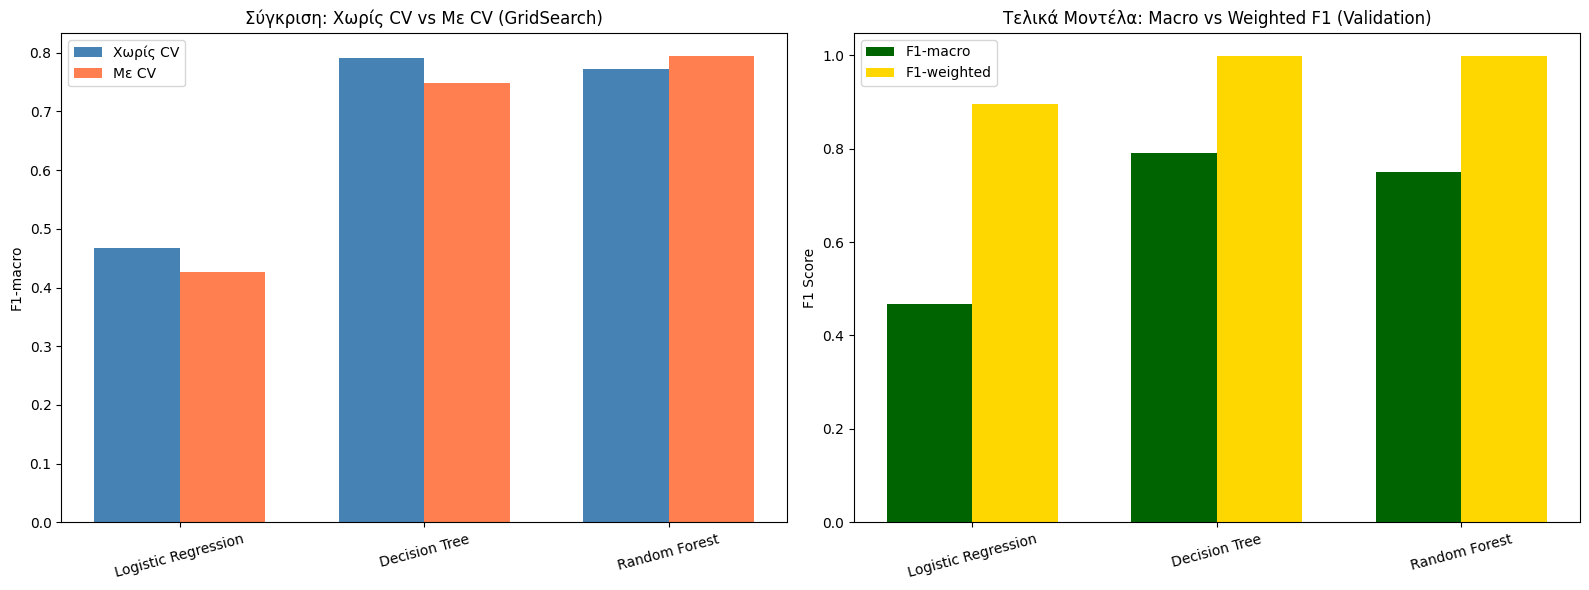

In [19]:
#Οπτικοποίηση
import matplotlib.pyplot as plt
import seaborn as sns
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

models = comparison_df['model']
x = np.arange(len(models))
width = 0.35

axes[0].bar(x - width/2, comparison_df['val_f1_macro_no_cv'], width, label='Χωρίς CV', color='steelblue')
axes[0].bar(x + width/2, comparison_df['cv_f1_macro'], width, label='Με CV', color='coral')
axes[0].set_xticks(x)
axes[0].set_xticklabels(models, rotation=15)
axes[0].set_ylabel('F1-macro')
axes[0].set_title('Σύγκριση: Χωρίς CV vs Με CV (GridSearch)')
axes[0].legend()

axes[1].bar(x - width/2, comparison_df['val_f1_macro_final'], width, label='F1-macro', color='darkgreen')
axes[1].bar(x + width/2, comparison_df['val_f1_weighted_final'], width, label='F1-weighted', color='gold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(models, rotation=15)
axes[1].set_ylabel('F1 Score')
axes[1].set_title('Τελικά Μοντέλα: Macro vs Weighted F1 (Validation)')
axes[1].legend()

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150)
plt.show()

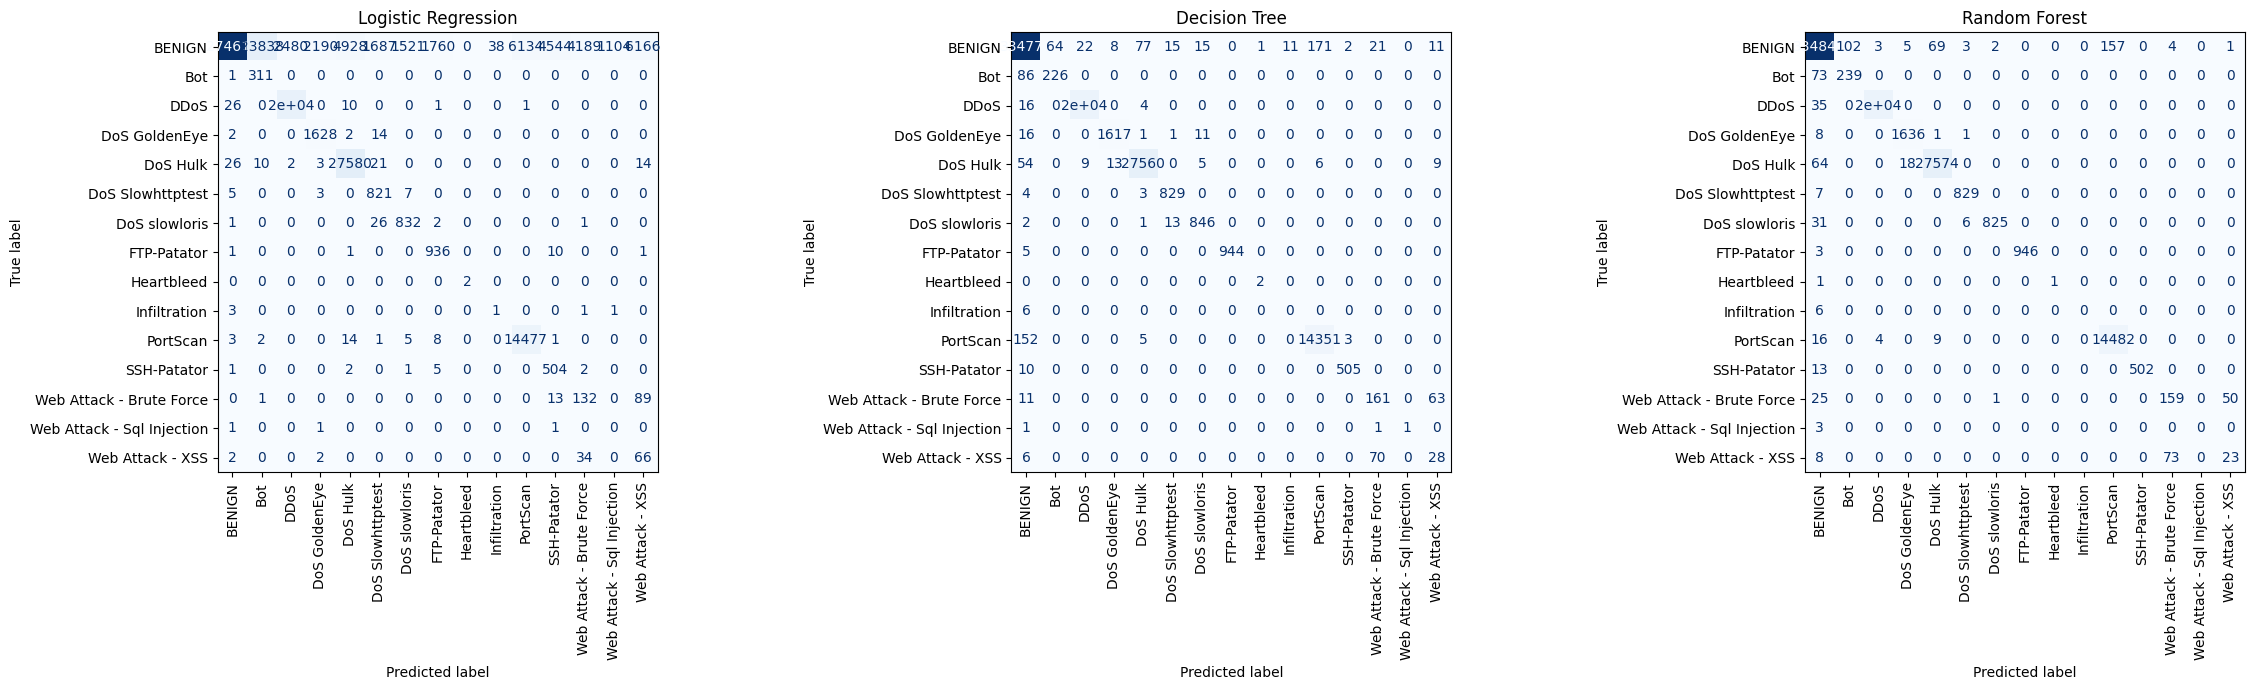

In [20]:
#Confusion Matrix για τα 3 μοντέλα στο validation
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(24, 7))
models_preds = [('Logistic Regression', val_pred_lr), ('Decision Tree', val_pred_dt),
                 ('Random Forest', val_pred_rf)]

for ax, (name, preds) in zip(axes, models_preds):
    cm = confusion_matrix(y_val, preds)
    disp = ConfusionMatrixDisplay(cm, display_labels=le.classes_)
    disp.plot(ax=ax, xticks_rotation=90, colorbar=False, cmap='Blues')
    ax.set_title(name)

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150)
plt.show()

In [24]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)
# Τελική εκπαίδευση στο πλήρες train set
# και αξιολόγηση στο ανεξάρτητο test set

final_logreg = LogisticRegression(max_iter=3000, class_weight='balanced', random_state=42, **grid_lr_cv.best_params_)
final_dt = DecisionTreeClassifier(class_weight='balanced', random_state=42, **grid_dt_cv.best_params_)
final_rf = RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1, **grid_rf_cv.best_params_)

final_models = {
    'Logistic Regression': final_logreg,

    'Decision Tree': final_dt,

    'Random Forest': final_rf
}

test_results = []

for name, model in final_models.items():

    print(f"\n{'*'*60}")
    print(name)
    print('*'*60)

    model.fit(X_train_scaled, y_train)
    test_pred_model = model.predict(X_test_scaled)


    accuracy = accuracy_score(y_test, test_pred_model)

    precision = precision_score(y_test, test_pred_model, average='macro', zero_division=0)

    recall = recall_score(y_test, test_pred_model, average='macro', zero_division=0)

    f1_macro = f1_score(y_test, test_pred_model, average='macro', zero_division=0)

    f1_weighted = f1_score(y_test, test_pred_model, average='weighted', zero_division=0)

    test_results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision_macro': precision,
        'Recall_macro': recall,
        'F1_macro': f1_macro,
        'F1_weighted': f1_weighted
        })

    print(classification_report(y_test, test_pred_model, target_names=le.classes_, zero_division=0))


test_results_df = pd.DataFrame(test_results)

print("\nΤΕΛΙΚΗ ΣΥΓΚΡΙΣΗ ΣΤΟ TEST SET:")
display(test_results_df.style.format({
    'Accuracy': '{:.4f}',
    'Precision_macro': '{:.4f}',
    'Recall_macro': '{:.4f}',
    'F1_macro': '{:.4f}',
    'F1_weighted': '{:.4f}'
}))


************************************************************
Logistic Regression
************************************************************
                            precision    recall  f1-score   support

                    BENIGN       1.00      0.82      0.90    418991
                       Bot       0.01      1.00      0.02       390
                      DDoS       0.89      1.00      0.94     25603
             DoS GoldenEye       0.44      0.99      0.61      2057
                  DoS Hulk       0.86      1.00      0.92     34569
          DoS Slowhttptest       0.35      0.99      0.52      1046
             DoS slowloris       0.21      0.98      0.35      1077
               FTP-Patator       0.55      0.99      0.71      1186
                Heartbleed       0.40      1.00      0.57         2
              Infiltration       0.01      0.71      0.03         7
                  PortScan       0.70      1.00      0.82     18139
               SSH-Patator       0.28   

,Model,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_weighted
0,Logistic Regression,0.8477,0.3841,0.8772,0.4614,0.8949
1,Decision Tree,0.9983,0.8836,0.8695,0.8738,0.9984
2,Random Forest,0.9985,0.9250,0.8417,0.8594,0.9985


## **Ερώτημα 3 Clustering**
### *3.1 Στρατηγική Δειγματοληψίας*
Λόγω του μεγέθους του dataset (2.520.691 εγγραφές) και της υψηλής υπολογιστικής
πολυπλοκότητας ορισμένων αλγορίθμων ομαδοποίησης (ιδίως Hierarchical Clustering,
πολυπλοκότητας O(n²) ή υψηλότερης), η ανάλυση πραγματοποιείται σε στρωματοποιημένο
δείγμα του dataset, διατηρώντας τις αναλογίες των κλάσεων της μεταβλητής Label
(η οποία χρησιμοποιείται αποκλειστικά εκ των υστέρων, για την ερμηνεία των
αποτελεσμάτων, όχι κατά την εκπαίδευση).

In [25]:
from sklearn.model_selection import train_test_split

CLUSTERING_SAMPLE_SIZE = 50000

df_selected = pd.read_csv('/content/data/cleaned_selected_dataset.csv')

X_cluster_full = df_selected.drop(columns=['Label'])
y_cluster_labels_full = df_selected['Label']

X_cluster, _, y_cluster_labels, _ = train_test_split(
    X_cluster_full, y_cluster_labels_full,
    train_size=CLUSTERING_SAMPLE_SIZE,
    stratify=y_cluster_labels_full,
    random_state=42
)

del df_selected, X_cluster_full, y_cluster_labels_full
gc.collect()

print(f"Δείγμα clustering: {X_cluster.shape}")
print(y_cluster_labels.value_counts())

Δείγμα clustering: (50000, 47)
Label
BENIGN                      41555
DoS Hulk                     3428
DDoS                         2539
PortScan                     1799
DoS GoldenEye                 204
FTP-Patator                   118
DoS slowloris                 107
DoS Slowhttptest              104
SSH-Patator                    64
Bot                            39
Web Attack - Brute Force       29
Web Attack - XSS               13
Infiltration                    1
Name: count, dtype: int64


In [26]:
# Scaling
from sklearn.preprocessing import StandardScaler

scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

print("Κλιμάκωση ολοκληρώθηκε.")
print(f"Shape: {X_cluster_scaled.shape}")

Κλιμάκωση ολοκληρώθηκε.
Shape: (50000, 47)


### *3.2 K-Means Clustering*
Εφαρμόζουμε τον αλγόριθμο K-Means διερευνώντας διαφορετικές τιμές του αριθμού
ομάδων k, χρησιμοποιώντας τη μέθοδο του αγκώνα (elbow method) και τον δείκτη
Silhouette για την επιλογή κατάλληλης τιμής.<br>
-> Elbow method και Silhouette για εύρος τιμών k:

In [27]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

k_range = range(2, 16)
inertias = []
silhouette_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster_scaled)
    inertias.append(km.inertia_)
    sil = silhouette_score(X_cluster_scaled, labels, sample_size=10000, random_state=42)
    silhouette_scores.append(sil)
    print(f"k={k}: inertia={km.inertia_:.0f}, silhouette={sil:.4f}")

k=2: inertia=1975013, silhouette=0.5305
k=3: inertia=1804534, silhouette=0.4489
k=4: inertia=1719321, silhouette=0.3023
k=5: inertia=1566346, silhouette=0.2851
k=6: inertia=1464094, silhouette=0.2847
k=7: inertia=1353039, silhouette=0.2987
k=8: inertia=1275862, silhouette=0.3236
k=9: inertia=1210373, silhouette=0.3034
k=10: inertia=1128163, silhouette=0.3630
k=11: inertia=1056075, silhouette=0.3241
k=12: inertia=997313, silhouette=0.3490
k=13: inertia=967027, silhouette=0.3648
k=14: inertia=892482, silhouette=0.3971
k=15: inertia=864568, silhouette=0.3892


-> Οπτικοποίηση:

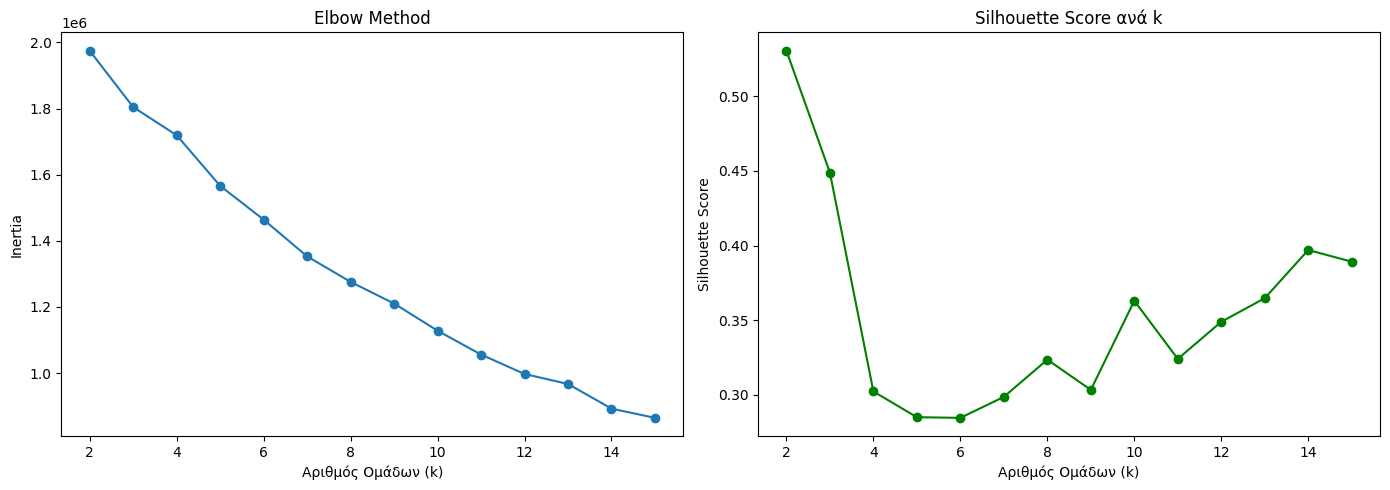

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_range), inertias, marker='o')
axes[0].set_xlabel('Αριθμός Ομάδων (k)')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Method')

axes[1].plot(list(k_range), silhouette_scores, marker='o', color='green')
axes[1].set_xlabel('Αριθμός Ομάδων (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score ανά k')

plt.tight_layout()
plt.savefig('kmeans_k_selection.png', dpi=150)
plt.show()

In [29]:
#Τελικό K-Means με k=2
from sklearn.metrics import davies_bouldin_score

kmeans_k2 = KMeans(n_clusters=2, random_state=42, n_init=10)
cluster_labels_k2 = kmeans_k2.fit_predict(X_cluster_scaled)

sil_k2 = silhouette_score(X_cluster_scaled, cluster_labels_k2, sample_size=10000, random_state=42)
db_k2 = davies_bouldin_score(X_cluster_scaled, cluster_labels_k2)

print(f"k=2: Silhouette={sil_k2:.4f}, Davies-Bouldin={db_k2:.4f}")

k=2: Silhouette=0.5305, Davies-Bouldin=1.6428


In [30]:
#Σύγκριση clusters (k=2) με πραγματικό Label
crosstab_k2 = pd.crosstab(y_cluster_labels.values, cluster_labels_k2,
                            rownames=['Πραγματική Κλάση'], colnames=['Cluster'])
print(crosstab_k2)

Cluster                       0     1
Πραγματική Κλάση                     
BENIGN                    39472  2083
Bot                          39     0
DDoS                       1987   552
DoS GoldenEye               154    50
DoS Hulk                    641  2787
DoS Slowhttptest             28    76
DoS slowloris                49    58
FTP-Patator                 118     0
Infiltration                  0     1
PortScan                   1798     1
SSH-Patator                  64     0
Web Attack - Brute Force     29     0
Web Attack - XSS             13     0


In [31]:
#Τελικό K-Means με k=15 (για σύγκριση με πραγματικές κλάσεις)
kmeans_k15 = KMeans(n_clusters=15, random_state=42, n_init=10)
cluster_labels_k15 = kmeans_k15.fit_predict(X_cluster_scaled)

sil_k15 = silhouette_score(X_cluster_scaled, cluster_labels_k15, sample_size=10000, random_state=42)
db_k15 = davies_bouldin_score(X_cluster_scaled, cluster_labels_k15)

print(f"k=15: Silhouette={sil_k15:.4f}, Davies-Bouldin={db_k15:.4f}")

crosstab_k15 = pd.crosstab(y_cluster_labels.values, cluster_labels_k15,
                             rownames=['Πραγματική Κλάση'], colnames=['Cluster'])
print(crosstab_k15)

k=15: Silhouette=0.3892, Davies-Bouldin=0.9899
Cluster                     0     1     2     3      4     5    6   7   8   \
Πραγματική Κλάση                                                             
BENIGN                    3475  3076  5610  6969  19267    33   80   1   1   
Bot                          1     0    10    27      1     0    0   0   0   
DDoS                         0     0     0     1    924   404    0   0   0   
DoS GoldenEye                0     0     0    50     21     0    0   0   0   
DoS Hulk                     0     5     6     2    338  1877  912   0   0   
DoS Slowhttptest             0    10     6     1      5     0   16   0   0   
DoS slowloris                2     2     2    42      0     2    4   0   0   
FTP-Patator                  0    41     0    77      0     0    0   0   0   
Infiltration                 1     0     0     0      0     0    0   0   0   
PortScan                     1    15     0  1766      3     0    0   0   0   
SSH-Patator      

### *3.3 Hierarchical Clustering*
Εφαρμόζουμε ιεραρχική ομαδοποίηση εξετάζοντας διαφορετικές μεθόδους σύνδεσης
(linkage criteria).<br>
-> Dendrogram:
(μικρότερο υποδείγμα λόγω υπολογιστικού κόστους O(n²))

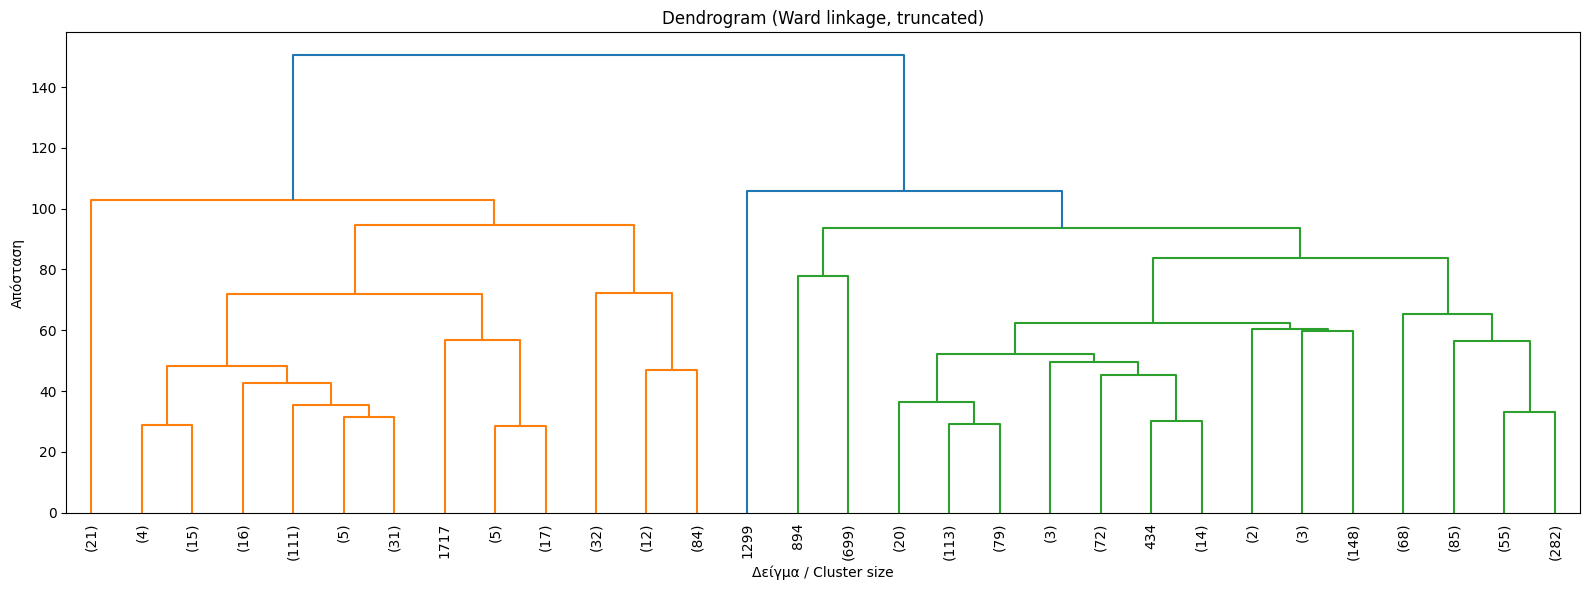

In [32]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

DENDRO_SAMPLE = 2000
X_dendro, _, y_dendro, _ = train_test_split(
    X_cluster_scaled, y_cluster_labels, train_size=DENDRO_SAMPLE,
    random_state=42
)

linked = linkage(X_dendro, method='ward')

plt.figure(figsize=(16, 6))
dendrogram(linked, truncate_mode='lastp', p=30, leaf_rotation=90)
plt.title('Dendrogram (Ward linkage, truncated)')
plt.xlabel('Δείγμα / Cluster size')
plt.ylabel('Απόσταση')
plt.tight_layout()
plt.savefig('dendrogram.png', dpi=150)
plt.show()

-> Σύγκριση linkage methods (στο πλήρες δείγμα 50Κ, με σταθερό k=2 για συνέπεια):

In [33]:
import pandas as pd
import numpy as np
import time
import gc
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage

df_selected = pd.read_csv('/content/data/cleaned_selected_dataset.csv')

CLUSTERING_SAMPLE_SIZE = 50000
X_cluster_full = df_selected.drop(columns=['Label'])
y_cluster_labels_full = df_selected['Label']

X_cluster, _, y_cluster_labels, _ = train_test_split(
    X_cluster_full, y_cluster_labels_full,
    train_size=CLUSTERING_SAMPLE_SIZE, stratify=y_cluster_labels_full, random_state=42
)

del df_selected, X_cluster_full, y_cluster_labels_full
gc.collect()

scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

print(f"Δείγμα clustering: {X_cluster_scaled.shape}")


Δείγμα clustering: (50000, 47)


In [34]:
HIER_SAMPLE = 5000
X_hier, _, y_hier, _ = train_test_split(
    X_cluster_scaled, y_cluster_labels, train_size=HIER_SAMPLE, random_state=42
)

linkage_methods = ['ward', 'complete', 'average']
hier_results = []

for method in linkage_methods:
    start = time.time()
    hc = AgglomerativeClustering(n_clusters=2, linkage=method)
    labels_hc = hc.fit_predict(X_hier)
    sil = silhouette_score(X_hier, labels_hc)
    db = davies_bouldin_score(X_hier, labels_hc)
    elapsed = time.time() - start
    hier_results.append({'linkage': method, 'silhouette': sil, 'davies_bouldin': db, 'time_s': elapsed})
    print(f"{method}: Silhouette={sil:.4f}, DB={db:.4f}, χρόνος={elapsed:.1f}s")

hier_results_df = pd.DataFrame(hier_results)
hier_results_df

ward: Silhouette=0.5145, DB=1.4044, χρόνος=3.2s
complete: Silhouette=0.9052, DB=0.0648, χρόνος=2.8s
average: Silhouette=0.9052, DB=0.0648, χρόνος=3.2s


,linkage,silhouette,davies_bouldin,time_s
0,ward,0.514460,1.404402,3.200081
1,complete,0.905217,0.064802,2.833622
2,average,0.905217,0.064802,3.170016


In [35]:
for method in linkage_methods:
    hc = AgglomerativeClustering(n_clusters=3, linkage=method)
    labels_hc = hc.fit_predict(X_hier)
    unique, counts = np.unique(labels_hc, return_counts=True)
    print(f"{method}: μεγέθη clusters = {dict(zip(unique, counts))}")

ward: μεγέθη clusters = {np.int64(0): np.int64(4605), np.int64(1): np.int64(336), np.int64(2): np.int64(59)}
complete: μεγέθη clusters = {np.int64(0): np.int64(4997), np.int64(1): np.int64(1), np.int64(2): np.int64(2)}
average: μεγέθη clusters = {np.int64(0): np.int64(4997), np.int64(1): np.int64(1), np.int64(2): np.int64(2)}


**Επιλογή μεθόδου σύνδεσης (linkage):**<br> Παρότι οι μέθοδοι complete και average εμφανίζουν υψηλότερο Silhouette Score (0,898 έναντι 0,509 της Ward), ο έλεγχος των μεγεθών των clusters δείχνει εκφυλισμένη λύση: 4.998 σημεία ανήκουν σε ένα cluster και από 1 σημείο στα άλλα δύο. Επομένως, δεν αξιολογούμε τις μεθόδους αποκλειστικά βάσει των μετρικών.

Η μέθοδος Ward δίνει clusters μεγέθους 4.530, 388 και 82 σημείων και αποτελεί πιο ερμηνεύσιμη λύση. Για τον λόγο αυτό επιλέγεται η Ward με k=2 για την τελική Hierarchical Clustering λύση.

In [36]:
hc_final = AgglomerativeClustering(n_clusters=2, linkage='ward')
labels_hc_final = hc_final.fit_predict(X_hier)

sil_hc = silhouette_score(X_hier, labels_hc_final)
db_hc = davies_bouldin_score(X_hier, labels_hc_final)
print(f"Ward (k=2): Silhouette={sil_hc:.4f}, Davies-Bouldin={db_hc:.4f}")

crosstab_hc = pd.crosstab(y_hier.values, labels_hc_final,
                            rownames=['Πραγματική Κλάση'], colnames=['Cluster'])
print(crosstab_hc)

Ward (k=2): Silhouette=0.5145, Davies-Bouldin=1.4044
Cluster                     0     1
Πραγματική Κλάση                   
BENIGN                     67  4085
Bot                         0     4
DDoS                       30   215
DoS GoldenEye               4    21
DoS Hulk                  290    70
DoS Slowhttptest            2    13
DoS slowloris               2     9
FTP-Patator                 0     7
PortScan                    0   168
SSH-Patator                 0     8
Web Attack - Brute Force    0     4
Web Attack - XSS            0     1


### *3.4 DBSCAN*
Εφαρμόζουμε τον αλγόριθμο DBSCAN, διερευνώντας τις παραμέτρους epsilon (ε) και
min_samples για τον εντοπισμό κατάλληλων ρυθμίσεων που οδηγούν σε ουσιαστικές
ομαδοποιήσεις, λαμβάνοντας ιδιαίτερα υπόψη την ικανότητα του αλγορίθμου να
εντοπίζει θόρυβο (noise points), σε αντίθεση με τους προηγούμενους αλγορίθμους.<br>
-> Εύρεση κατάλληλου epsilon μέσω k-distance graph:

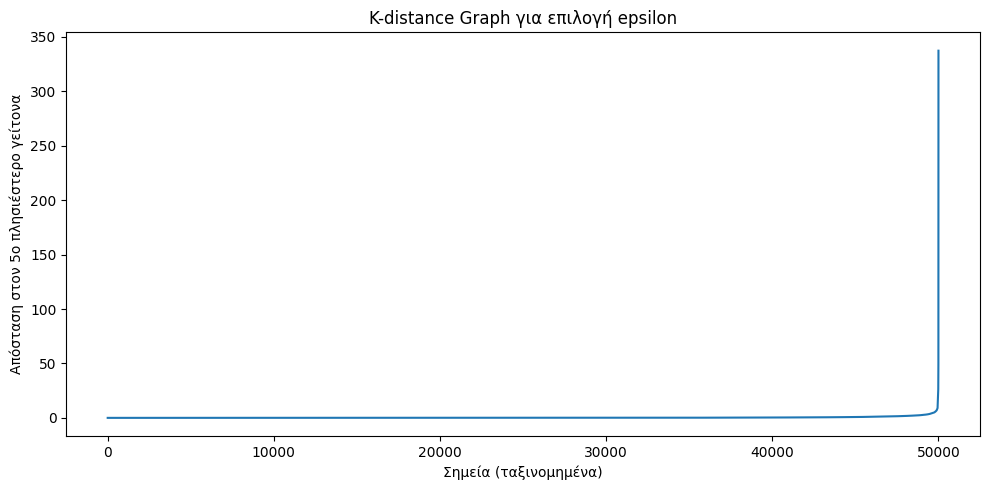

In [37]:
from sklearn.neighbors import NearestNeighbors

# Χρησιμοποιούμε το ίδιο δείγμα X_cluster_scaled (50.000) - DBSCAN είναι πιο αποδοτικό μνημονικά από Hierarchical
k = 5  # συνήθως ίσο με min_samples - 1 ή min_samples
neighbors = NearestNeighbors(n_neighbors=k)
neighbors_fit = neighbors.fit(X_cluster_scaled)
distances, indices = neighbors_fit.kneighbors(X_cluster_scaled)

distances = np.sort(distances[:, k-1])

plt.figure(figsize=(10, 5))
plt.plot(distances)
plt.xlabel('Σημεία (ταξινομημένα)')
plt.ylabel(f'Απόσταση στον {k}ο πλησιέστερο γείτονα')
plt.title('K-distance Graph για επιλογή epsilon')
plt.tight_layout()
plt.savefig('dbscan_kdistance.png', dpi=150)
plt.show()

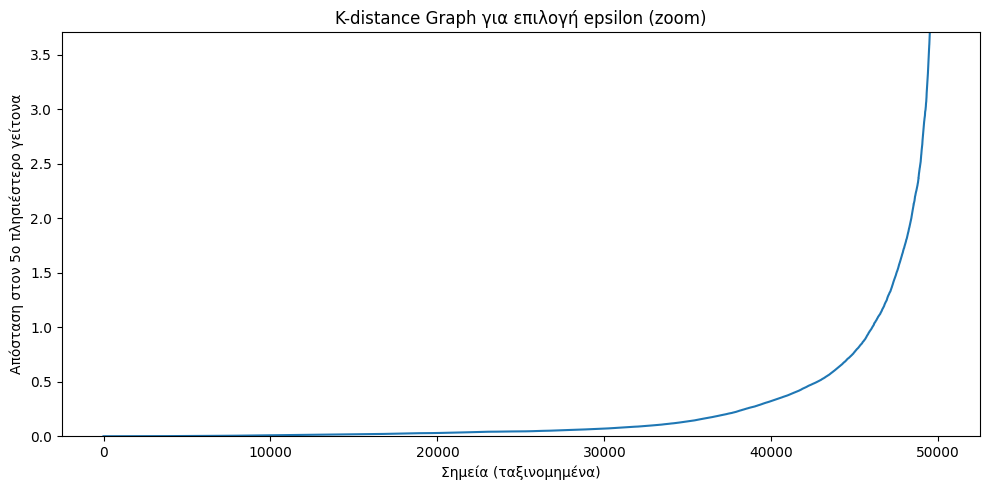

90ο ποσοστημόριο: 0.7756
95ο ποσοστημόριο: 1.4973
97ο ποσοστημόριο: 2.0991
99ο ποσοστημόριο: 3.7042
99.5ο ποσοστημόριο: 5.0554
99.9ο ποσοστημόριο: 10.1961


In [38]:
plt.figure(figsize=(10, 5))
plt.plot(distances)
plt.xlabel('Σημεία (ταξινομημένα)')
plt.ylabel(f'Απόσταση στον {k}ο πλησιέστερο γείτονα')
plt.title('K-distance Graph για επιλογή epsilon (zoom)')
plt.ylim(0, np.percentile(distances, 99))  # αγνοούμε το ακραίο 1% για να δούμε τον αγκώνα
plt.tight_layout()
plt.savefig('dbscan_kdistance_zoom.png', dpi=150)
plt.show()

# Επιπλέον: τυπώνουμε μερικά ενδεικτικά ποσοστημόρια για αριθμητική καθοδήγηση
for p in [90, 95, 97, 99, 99.5, 99.9]:
    print(f"{p}ο ποσοστημόριο: {np.percentile(distances, p):.4f}")

-> Δοκιμή πολλαπλών συνδυασμών epsilon/min_samples:

In [39]:
from sklearn.cluster import DBSCAN

eps_values = [0.5, 0.8, 1.0, 1.5, 2.0]
min_samples_values = [5, 10, 20]

dbscan_results = []

for eps in eps_values:
    for min_samples in min_samples_values:
        db = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=-1)
        labels_db = db.fit_predict(X_cluster_scaled)

        # Αριθμός clusters χωρίς το noise
        n_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)

        # Αριθμός και ποσοστό noise
        n_noise = list(labels_db).count(-1)
        noise_pct = n_noise / len(labels_db) * 100

        result = {'eps': eps, 'min_samples': min_samples,
                   'n_clusters': n_clusters, 'n_noise': n_noise, 'noise_pct': noise_pct}



        mask = labels_db != -1
        # Silhouette μόνο αν υπάρχουν τουλάχιστον 2 clusters (χωρίς το noise)
        if n_clusters >= 2 and mask.sum() > 1:

            sil = silhouette_score(X_cluster_scaled[mask], labels_db[mask], sample_size=min(10000, mask.sum()), random_state=42)
            db_index = davies_bouldin_score(X_cluster_scaled[mask], labels_db[mask])

            result['silhouette'] = sil
            result['davies_bouldin'] = db_index

        else:
            result['silhouette'] = np.nan
            result['davies_bouldin'] = np.nan

        dbscan_results.append(result)

        print(
            f"eps={eps}, min_samples={min_samples}: "
            f"clusters={n_clusters}, "
            f"noise={n_noise} ({noise_pct:.1f}%), "
            f"silhouette={result['silhouette']}, "
            f"Davies-Bouldin={result['davies_bouldin']}"
        )

dbscan_results_df = pd.DataFrame(dbscan_results)

display(dbscan_results_df)

eps=0.5, min_samples=5: clusters=400, noise=6289 (12.6%), silhouette=0.44895866403243345, Davies-Bouldin=0.55680358627653
eps=0.5, min_samples=10: clusters=233, noise=8306 (16.6%), silhouette=0.5091991494975803, Davies-Bouldin=0.5039997558495514
eps=0.5, min_samples=20: clusters=130, noise=10776 (21.6%), silhouette=0.5400761528993652, Davies-Bouldin=0.5003644250114888
eps=0.8, min_samples=5: clusters=259, noise=4215 (8.4%), silhouette=0.20893086647030168, Davies-Bouldin=0.5974390936377592
eps=0.8, min_samples=10: clusters=149, noise=5349 (10.7%), silhouette=0.2399279693812463, Davies-Bouldin=0.6196581457960756
eps=0.8, min_samples=20: clusters=97, noise=6895 (13.8%), silhouette=0.39729249592643134, Davies-Bouldin=0.6592853838415771
eps=1.0, min_samples=5: clusters=223, noise=3356 (6.7%), silhouette=0.1261303646558619, Davies-Bouldin=0.6902286515611741
eps=1.0, min_samples=10: clusters=130, noise=4371 (8.7%), silhouette=0.16455666665089375, Davies-Bouldin=0.7316402740336487
eps=1.0, min

,eps,min_samples,n_clusters,n_noise,noise_pct,silhouette,davies_bouldin
0,0.5,5,400,6289,12.578,0.448959,0.556804
1,0.5,10,233,8306,16.612,0.509199,0.504000
2,0.5,20,130,10776,21.552,0.540076,0.500364
3,0.8,5,259,4215,8.430,0.208931,0.597439
4,0.8,10,149,5349,10.698,0.239928,0.619658
5,0.8,20,97,6895,13.790,0.397292,0.659285
6,1.0,5,223,3356,6.712,0.126130,0.690229
7,1.0,10,130,4371,8.742,0.164557,0.731640
8,1.0,20,85,5517,11.034,0.185487,0.797529
9,1.5,5,164,2077,4.154,0.156635,0.703156


In [43]:
db_final = DBSCAN(eps=2.0, min_samples=20, n_jobs=-1)
labels_db_final = db_final.fit_predict(X_cluster_scaled)

n_clusters_final = len(set(labels_db_final)) - (1 if -1 in labels_db_final else 0)
n_noise_final = list(labels_db_final).count(-1)
print(f"Αριθμός clusters: {n_clusters_final}")
print(f"Θόρυβος (noise): {n_noise_final} ({n_noise_final/len(labels_db_final)*100:.1f}%)")

# Πολύ σημαντικό: ελέγχουμε αν ο "θόρυβος" περιέχει δυσανάλογα πολλές επιθέσεις
noise_mask = labels_db_final == -1
print("\nΚατανομή Label ΜΕΣΑ στον θόρυβο (noise points):")
print(y_cluster_labels[noise_mask].value_counts())

print("\nΠοσοστό κάθε κλάσης που ταξινομήθηκε ως θόρυβος:")
for cls in y_cluster_labels.unique():
    total = (y_cluster_labels == cls).sum()
    noise_count = ((y_cluster_labels == cls) & noise_mask).sum()
    print(f"  {cls}: {noise_count}/{total} ({noise_count/total*100:.1f}%)")

# Davies-Bouldin Index για DBSCAN
# Υπολογίζεται μόνο στα σημεία που δεν χαρακτηρίστηκαν ως noise
non_noise_mask = labels_db_final != -1

X_dbscan_eval = X_cluster_scaled[non_noise_mask]
labels_dbscan_eval = labels_db_final[non_noise_mask]

# Έλεγχος για NaN / Inf
print("NaN values:", np.isnan(X_dbscan_eval).sum())
print("Inf values:", np.isinf(X_dbscan_eval).sum())

# Μεγέθη clusters
cluster_sizes_dbscan = pd.Series(labels_dbscan_eval).value_counts().sort_index()
print("\nCluster sizes:")
print(cluster_sizes_dbscan)

if len(np.unique(labels_dbscan_eval)) >= 2:
    db_dbscan = davies_bouldin_score(
        X_dbscan_eval,
        labels_dbscan_eval
    )
    print(f"\nDBSCAN Davies-Bouldin Index (χωρίς noise): {db_dbscan:.4f}")
else:
    db_dbscan = np.nan
    print("\nΔεν είναι δυνατός ο υπολογισμός Davies-Bouldin.")

Αριθμός clusters: 29
Θόρυβος (noise): 2568 (5.1%)

Κατανομή Label ΜΕΣΑ στον θόρυβο (noise points):
Label
BENIGN                      2212
DDoS                          76
DoS Hulk                      74
DoS GoldenEye                 72
DoS slowloris                 61
DoS Slowhttptest              36
PortScan                      32
Web Attack - Brute Force       3
Infiltration                   1
Bot                            1
Name: count, dtype: int64

Ποσοστό κάθε κλάσης που ταξινομήθηκε ως θόρυβος:
  PortScan: 32/1799 (1.8%)
  BENIGN: 2212/41555 (5.3%)
  DDoS: 76/2539 (3.0%)
  DoS Hulk: 74/3428 (2.2%)
  DoS GoldenEye: 72/204 (35.3%)
  DoS Slowhttptest: 36/104 (34.6%)
  DoS slowloris: 61/107 (57.0%)
  FTP-Patator: 0/118 (0.0%)
  Web Attack - Brute Force: 3/29 (10.3%)
  SSH-Patator: 0/64 (0.0%)
  Infiltration: 1/1 (100.0%)
  Web Attack - XSS: 0/13 (0.0%)
  Bot: 1/39 (2.6%)
NaN values: 0
Inf values: 0

Cluster sizes:
0     11796
1     17955
2      5476
3      4444
4      1748
5    

In [44]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_cluster_scaled)

print(f"Εξηγούμενη διακύμανση: {pca.explained_variance_ratio_}")
print(f"Συνολική εξηγούμενη διακύμανση (2 components): {pca.explained_variance_ratio_.sum():.2%}")

Εξηγούμενη διακύμανση: [0.18352245 0.09677147]
Συνολική εξηγούμενη διακύμανση (2 components): 28.03%


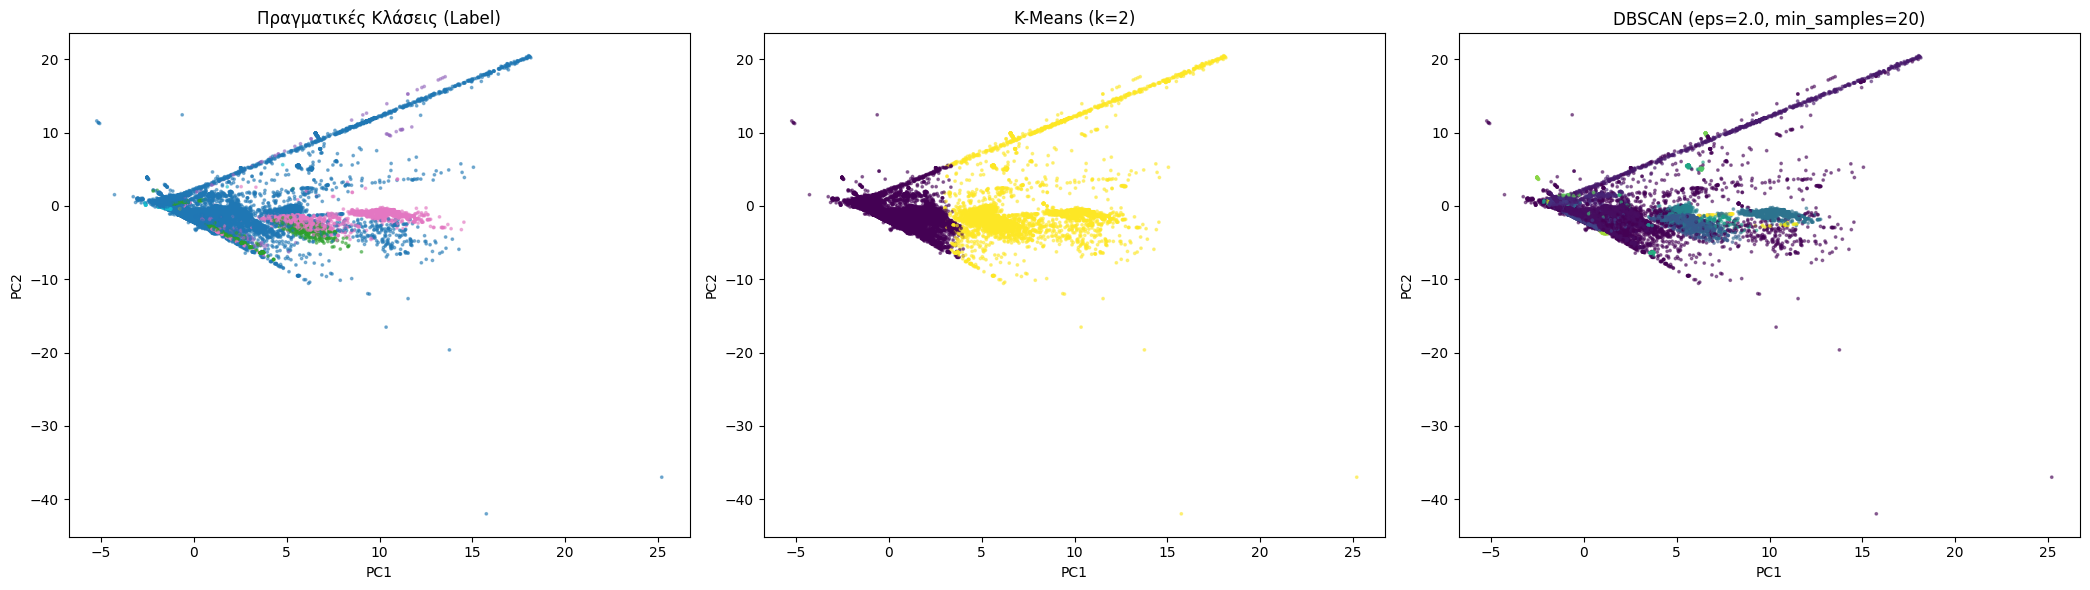

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# 1. Πραγματικό Label (μόνο οι κύριες κλάσεις για ευανάγνωστο plot)
top_classes = y_cluster_labels.value_counts().head(6).index
mask_top = y_cluster_labels.isin(top_classes)
scatter1 = axes[0].scatter(X_pca[mask_top, 0], X_pca[mask_top, 1],
                             c=pd.Categorical(y_cluster_labels[mask_top]).codes,
                             cmap='tab10', s=3, alpha=0.5)
axes[0].set_title('Πραγματικές Κλάσεις (Label)')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

# 2. K-Means (k=2)
kmeans_final = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans_pca_labels = kmeans_final.fit_predict(X_cluster_scaled)
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_pca_labels, cmap='viridis', s=3, alpha=0.5)
axes[1].set_title('K-Means (k=2)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

# 3. DBSCAN
axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_db_final, cmap='viridis', s=3, alpha=0.5)
axes[2].set_title('DBSCAN (eps=2.0, min_samples=20)')
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')

plt.tight_layout()
plt.savefig('pca_comparison.png', dpi=150)
plt.show()

In [46]:
clustering_comparison = pd.DataFrame([
    {'algorithm': 'K-Means (k=2)', 'n_clusters': 2, 'silhouette': sil_k2,
     'davies_bouldin': db_k2, 'noise_handling': 'Όχι'},
    {'algorithm': 'Hierarchical (ward, k=2)', 'n_clusters': 2, 'silhouette': sil_hc,
     'davies_bouldin': db_hc, 'noise_handling': 'Όχι'},
    {'algorithm': 'DBSCAN (eps=2.0, min_samples=20)', 'n_clusters': n_clusters_final,
     'silhouette': dbscan_results_df[(dbscan_results_df['eps']==2.0) &
                    (dbscan_results_df['min_samples']==20)]['silhouette'].values[0],
     'davies_bouldin': db_dbscan, 'noise_handling': f'Ναι ({n_noise_final} σημεία, {n_noise_final/len(labels_db_final)*100:.1f}%)'}
])
clustering_comparison

,algorithm,n_clusters,silhouette,davies_bouldin,noise_handling
0,K-Means (k=2),2,0.530531,1.642811,Όχι
1,"Hierarchical (ward, k=2)",2,0.514460,1.404402,Όχι
2,"DBSCAN (eps=2.0, min_samples=20)",29,0.391359,0.607969,"Ναι (2568 σημεία, 5.1%)"
